<a href="https://colab.research.google.com/github/oabdelhalim8/ML---1/blob/main/ML_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import sys

assert sys.version_info >= (3, 10)

In [3]:
from packaging.version import Version
import sklearn

assert Version(sklearn.__version__) >= Version("1.6.1")

In [4]:
from pathlib import Path
import pandas as pd
import tarfile
import urllib.request

def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path="datasets", filter="data")
    return pd.read_csv(Path("datasets/housing/housing.csv"))

housing_full = load_housing_data()

In [5]:
housing_full.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.00,-0.92,-0.11,0.04,0.07,0.10,0.06,-0.02,-0.05
latitude,-0.92,1.00,0.01,-0.04,-0.07,-0.11,-0.07,-0.08,-0.14
housing_median_age,-0.11,0.01,1.00,-0.36,-0.32,-0.30,-0.30,-0.12,0.11
total_rooms,0.04,-0.04,-0.36,1.00,0.93,0.86,0.92,0.20,0.13
total_bedrooms,0.07,-0.07,-0.32,0.93,1.00,0.88,0.98,-0.01,0.05
population,0.10,-0.11,-0.30,0.86,0.88,1.00,0.91,0.00,-0.02
households,0.06,-0.07,-0.30,0.92,0.98,0.91,1.00,0.01,0.07
median_income,-0.02,-0.08,-0.12,0.20,-0.01,0.00,0.01,1.00,0.69
median_house_value,-0.05,-0.14,0.11,0.13,0.05,-0.02,0.07,0.69,1.00


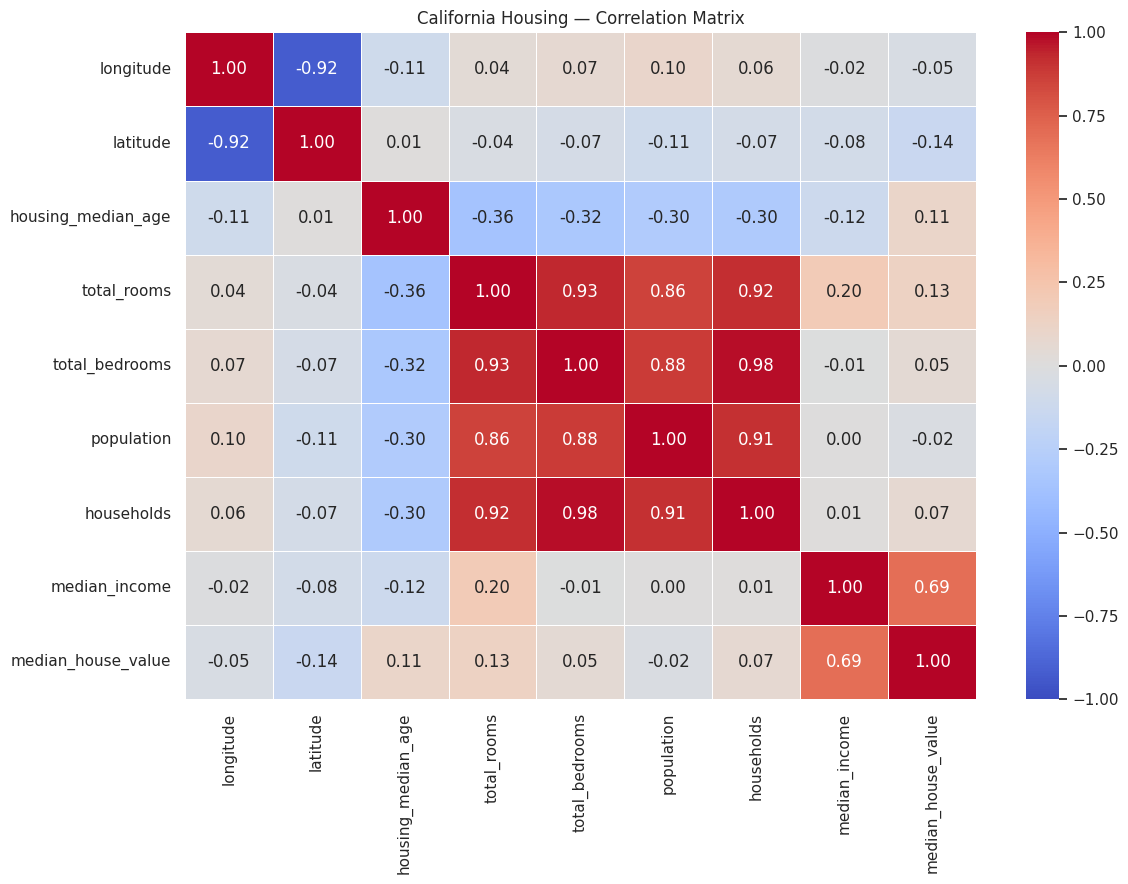

In [6]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns and calculate correlations
corr_matrix = housing_full.select_dtypes(include="number").corr()

# Display the correlation matrix
display(corr_matrix.round(2))

# Create a correlation heatmap
sns.set_theme(style="dark")

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("California Housing — Correlation Matrix")
plt.tight_layout()
plt.show()


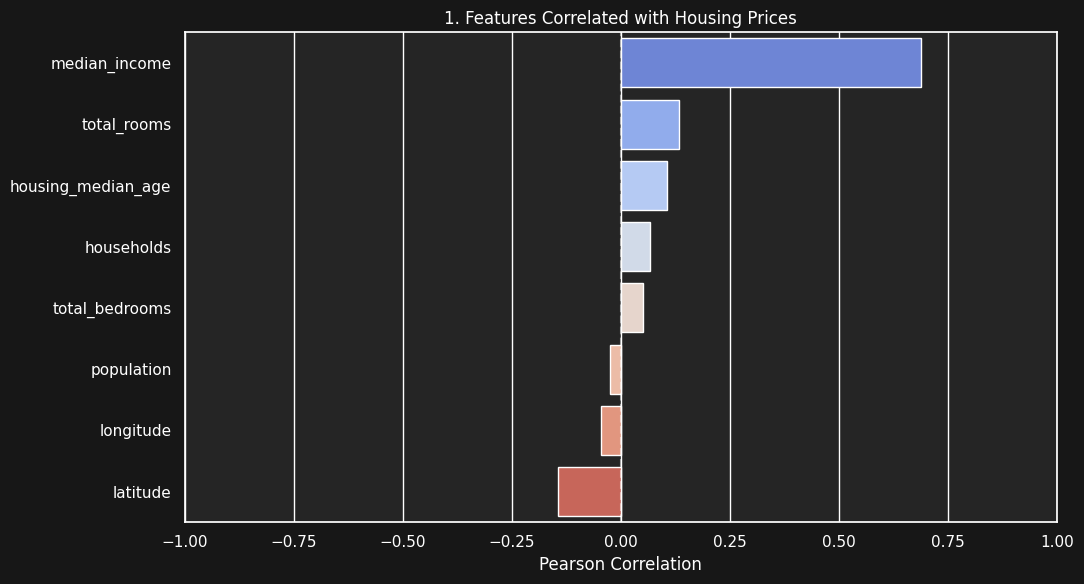

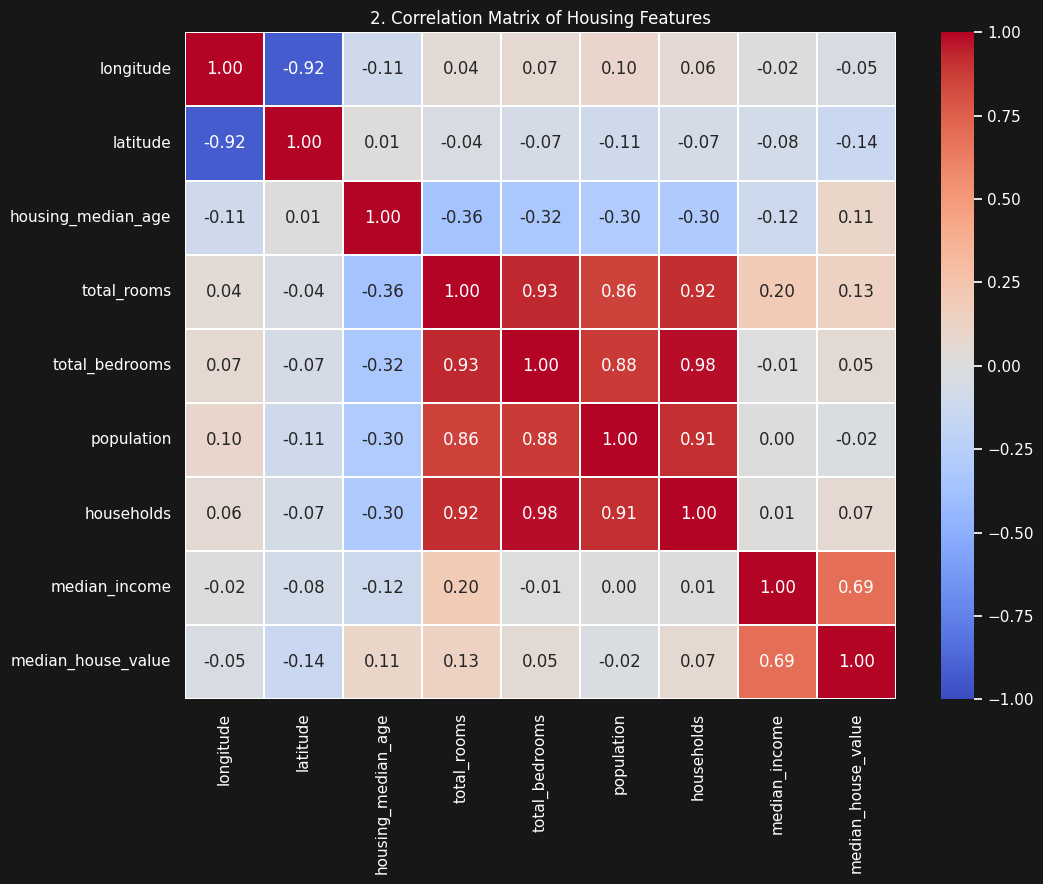

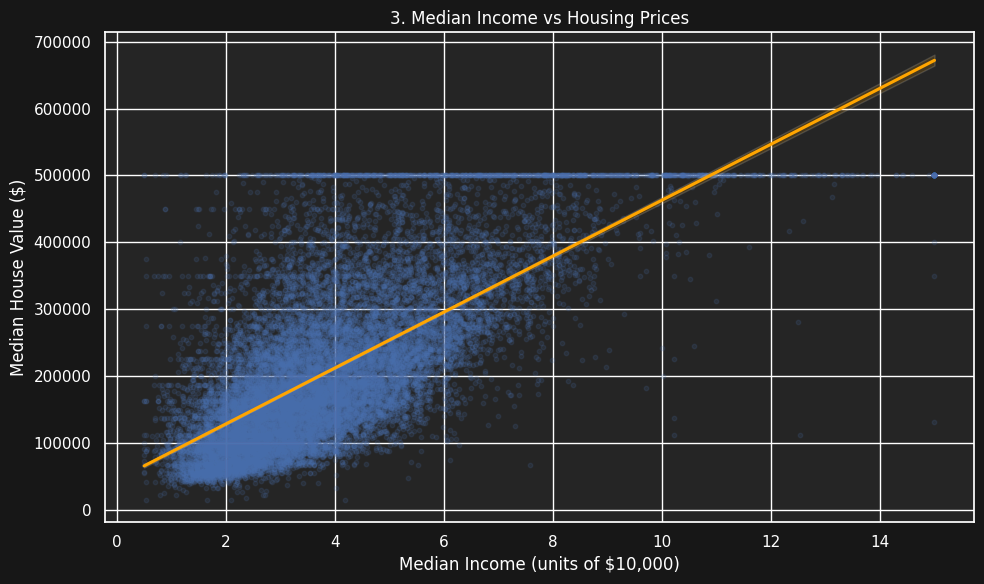

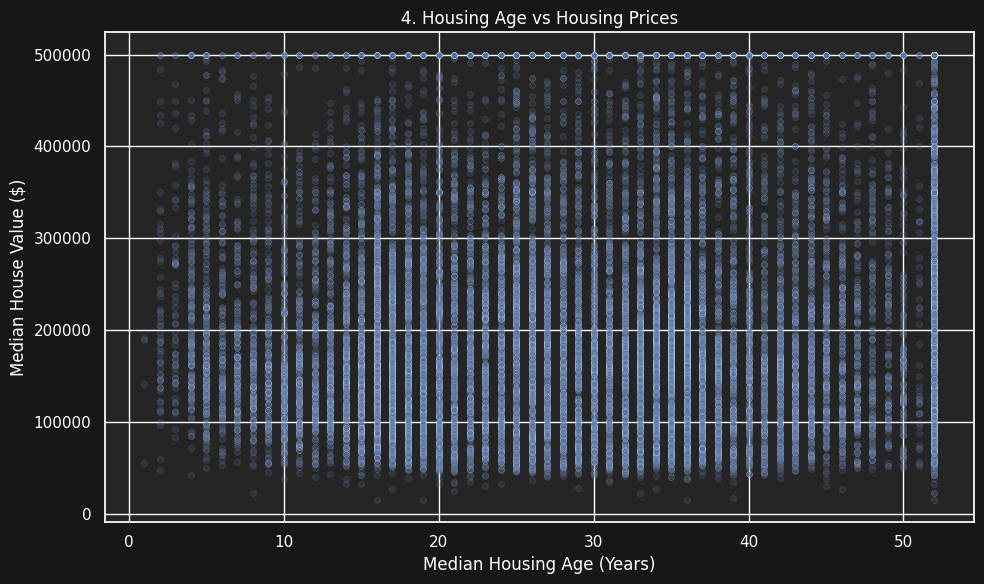

In [7]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Dark theme
sns.set_theme(style="darkgrid", palette="deep")
plt.rcParams.update({
    "figure.facecolor": "#171717",
    "axes.facecolor": "#252525",
    "axes.labelcolor": "white",
    "text.color": "white",
    "xtick.color": "white",
    "ytick.color": "white"
})

# Calculate correlations
corr_matrix = housing_full.select_dtypes(include="number").corr()

price_corr = (
    corr_matrix["median_house_value"]
    .drop("median_house_value")
    .sort_values(ascending=False)
)

# CHART 1: Correlation ranking
plt.figure(figsize=(11, 6))
sns.barplot(
    x=price_corr.values,
    y=price_corr.index,
    hue=price_corr.index,
    palette="coolwarm",
    legend=False
)
plt.axvline(0, color="white", linestyle="--", alpha=0.5)
plt.xlim(-1, 1)
plt.title("1. Features Correlated with Housing Prices")
plt.xlabel("Pearson Correlation")
plt.ylabel("")
plt.tight_layout()
plt.show()


# CHART 2: Full correlation heatmap
plt.figure(figsize=(11, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3
)
plt.title("2. Correlation Matrix of Housing Features")
plt.tight_layout()
plt.show()


# CHART 3: Income vs Housing Prices
plt.figure(figsize=(10, 6))
sns.regplot(
    data=housing_full,
    x="median_income",
    y="median_house_value",
    scatter_kws={"alpha": 0.15, "s": 10},
    line_kws={"color": "orange"}
)
plt.title("3. Median Income vs Housing Prices")
plt.xlabel("Median Income (units of $10,000)")
plt.ylabel("Median House Value ($)")
plt.tight_layout()
plt.show()


# CHART 4: Housing Age vs Housing Prices
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=housing_full,
    x="housing_median_age",
    y="median_house_value",
    alpha=0.2,
    s=18
)
plt.title("4. Housing Age vs Housing Prices")
plt.xlabel("Median Housing Age (Years)")
plt.ylabel("Median House Value ($)")
plt.tight_layout()
plt.show()


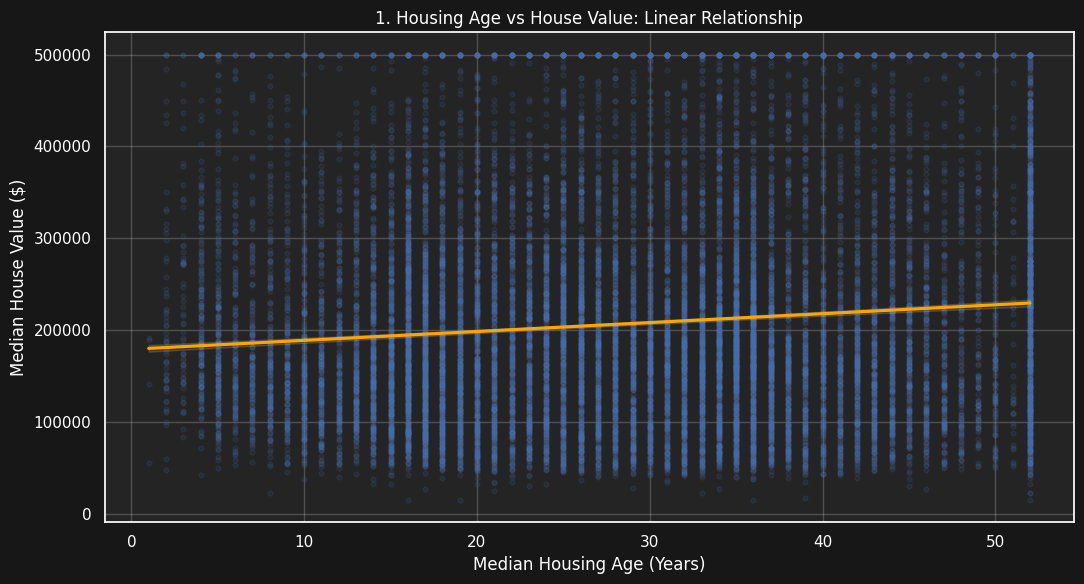

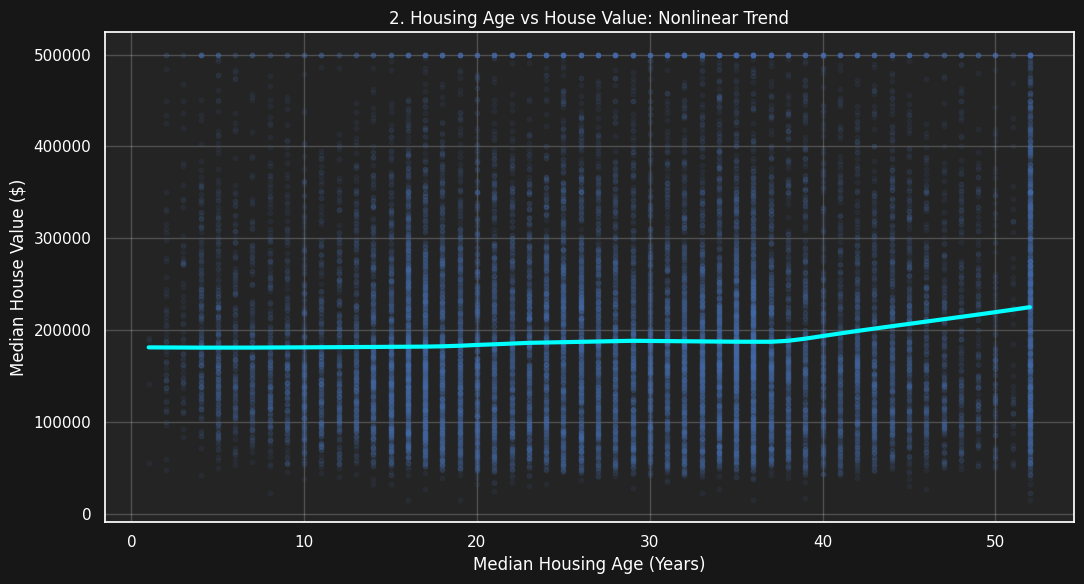

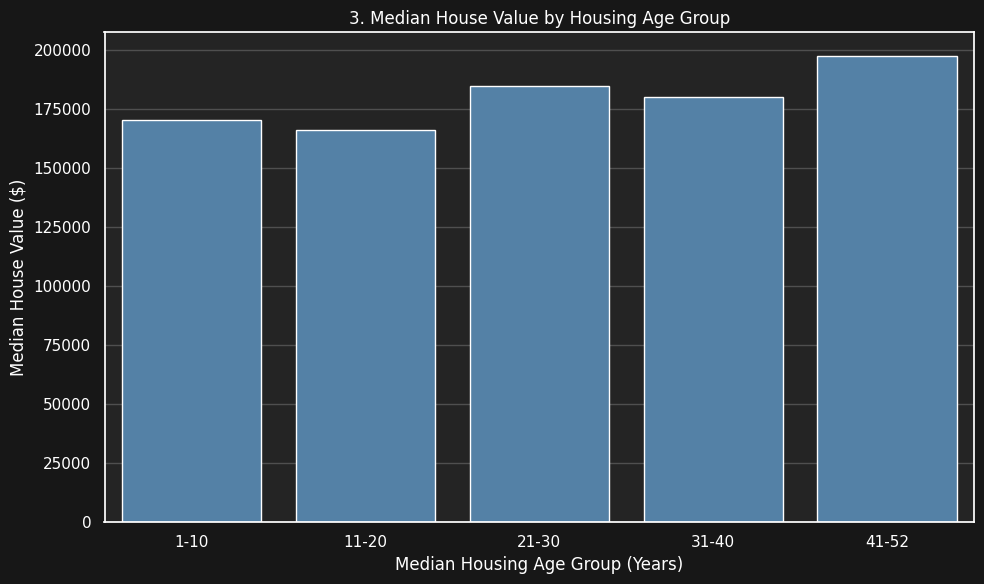

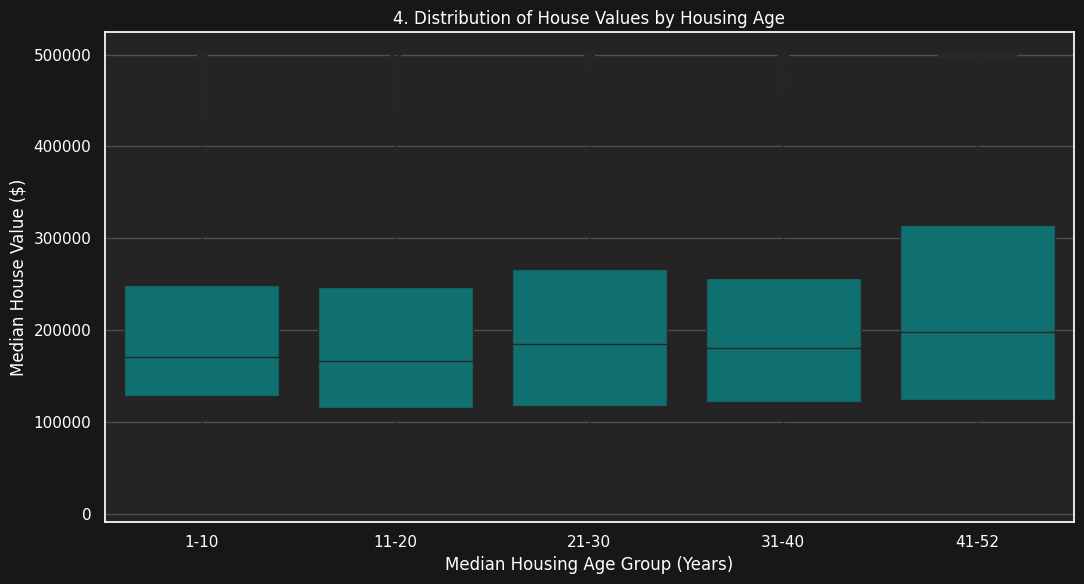

In [8]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare the data
df = housing_full[
    ["housing_median_age", "median_house_value"]
].dropna().copy()

# Set dark theme
sns.set_theme(style="darkgrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": "#171717",
    "axes.facecolor": "#242424",
    "axes.labelcolor": "white",
    "text.color": "white",
    "xtick.color": "white",
    "ytick.color": "white",
    "grid.alpha": 0.2
})

# CHART 1: Scatterplot with linear regression
plt.figure(figsize=(11, 6))
sns.regplot(
    data=df,
    x="housing_median_age",
    y="median_house_value",
    scatter_kws={"alpha": 0.12, "s": 12},
    line_kws={"color": "orange"}
)
plt.title("1. Housing Age vs House Value: Linear Relationship")
plt.xlabel("Median Housing Age (Years)")
plt.ylabel("Median House Value ($)")
plt.tight_layout()
plt.show()


# CHART 2: Nonlinear relationship using LOWESS
plt.figure(figsize=(11, 6))
sns.regplot(
    data=df,
    x="housing_median_age",
    y="median_house_value",
    lowess=True,
    scatter_kws={"alpha": 0.08, "s": 10},
    line_kws={"color": "cyan", "linewidth": 3}
)
plt.title("2. Housing Age vs House Value: Nonlinear Trend")
plt.xlabel("Median Housing Age (Years)")
plt.ylabel("Median House Value ($)")
plt.tight_layout()
plt.show()


# CHART 3: Median house value by age group
df["age_group"] = pd.cut(
    df["housing_median_age"],
    bins=[0, 10, 20, 30, 40, 53],
    labels=["1-10", "11-20", "21-30", "31-40", "41-52"]
)

age_summary = (
    df.groupby("age_group", observed=True)["median_house_value"]
    .median()
    .reset_index()
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=age_summary,
    x="age_group",
    y="median_house_value",
    color="steelblue"
)
plt.title("3. Median House Value by Housing Age Group")
plt.xlabel("Median Housing Age Group (Years)")
plt.ylabel("Median House Value ($)")
plt.tight_layout()
plt.show()


# CHART 4: Price distribution by age group
plt.figure(figsize=(11, 6))
sns.boxplot(
    data=df,
    x="age_group",
    y="median_house_value",
    color="teal"
)
plt.title("4. Distribution of House Values by Housing Age")
plt.xlabel("Median Housing Age Group (Years)")
plt.ylabel("Median House Value ($)")
plt.tight_layout()
plt.show()


In [9]:

pearson = df["housing_median_age"].corr(
    df["median_house_value"], method="pearson"
)

spearman = df["housing_median_age"].corr(
    df["median_house_value"], method="spearman"
)

print(f"Pearson correlation:  {pearson:.3f}")
print(f"Spearman correlation: {spearman:.3f}")


Pearson correlation:  0.106
Spearman correlation: 0.075


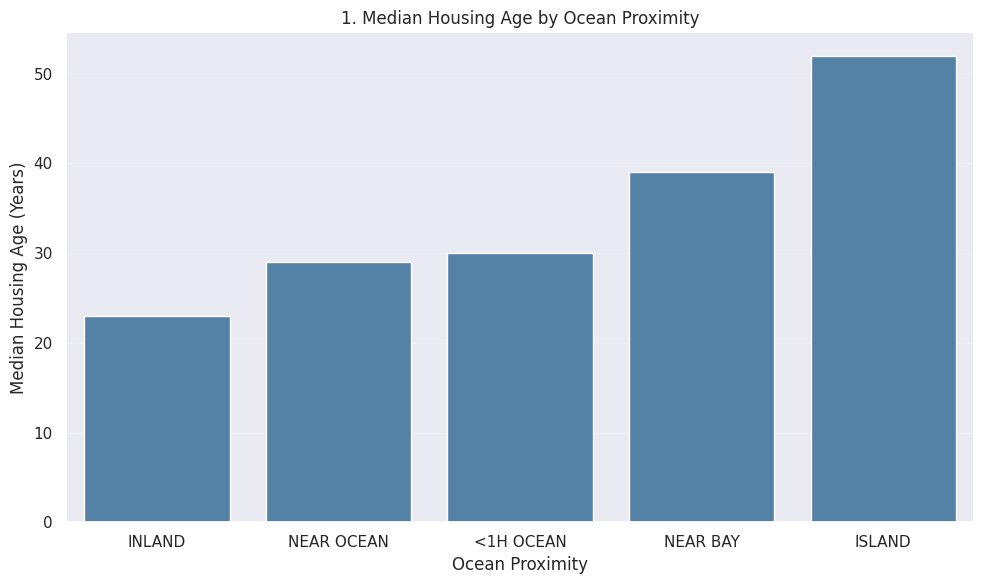

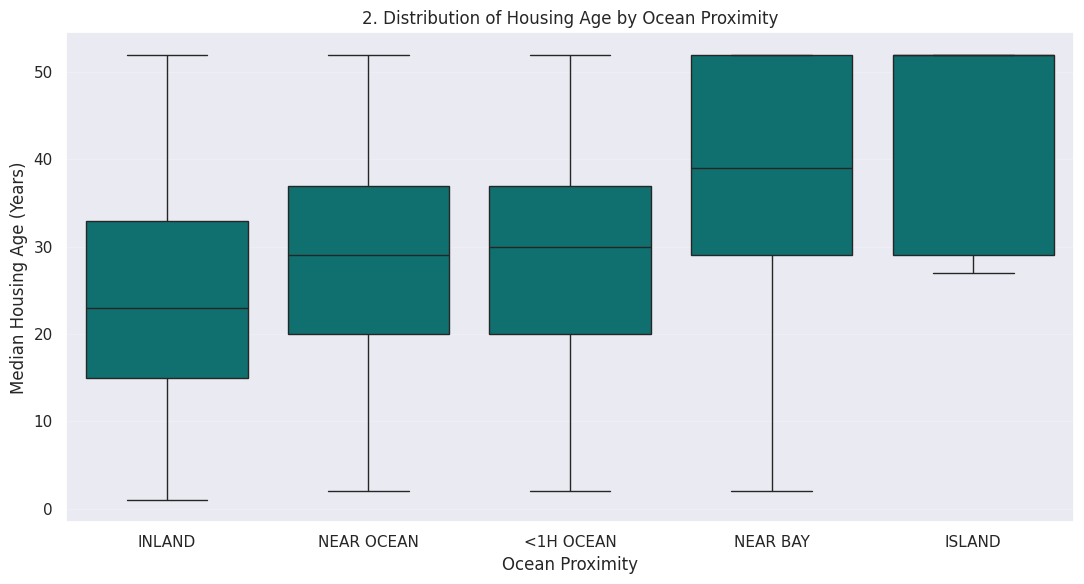

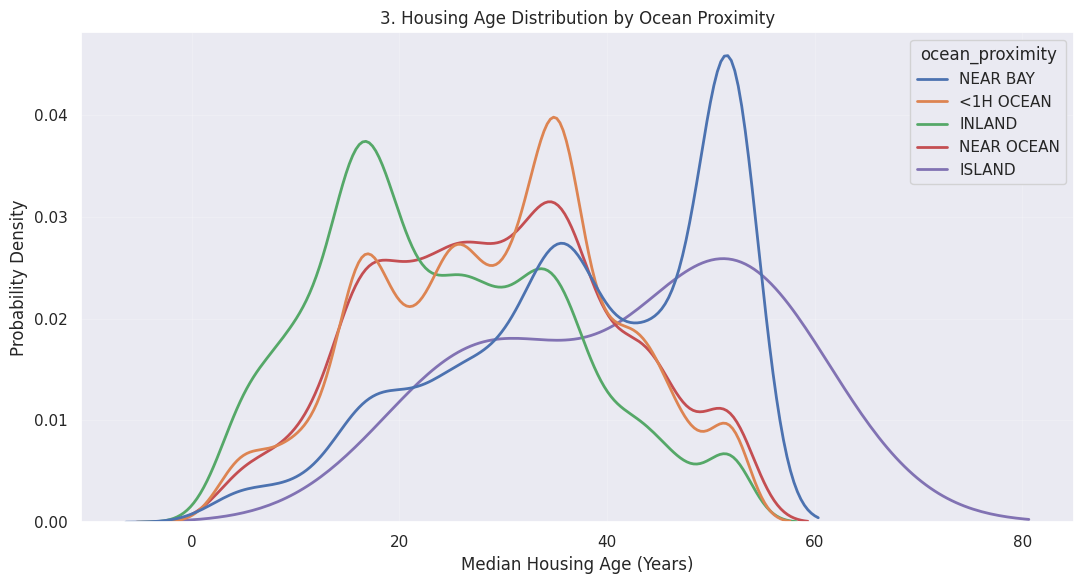

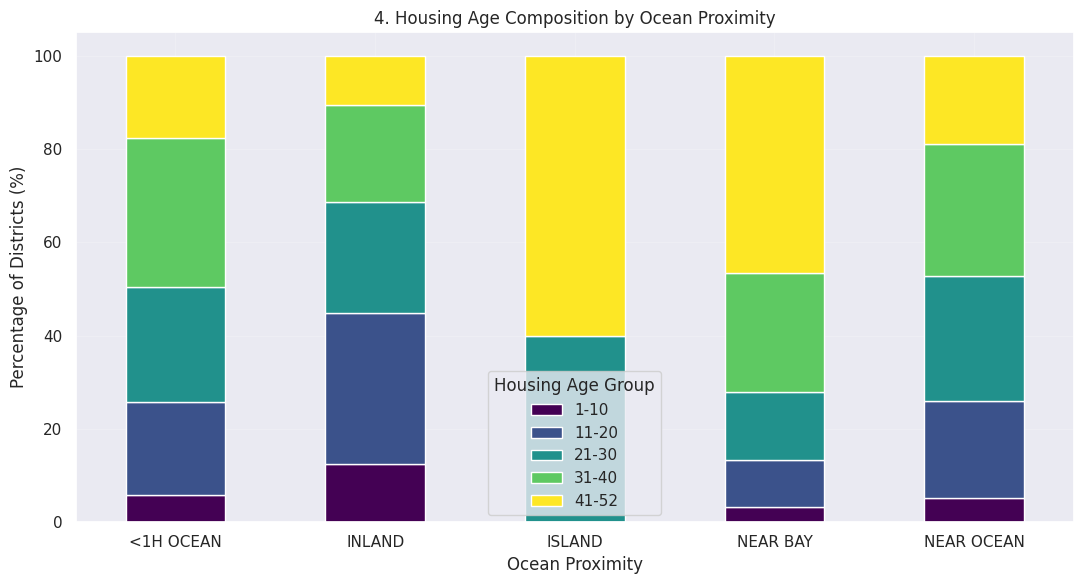

In [10]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare the dataset
df = housing_full[
    ["housing_median_age", "ocean_proximity"]
].dropna().copy()

# Set visual style
sns.set_theme(style="darkgrid")

# Sort ocean categories by median housing age
ocean_order = (
    df.groupby("ocean_proximity")["housing_median_age"]
    .median()
    .sort_values()
    .index
)

# CHART 1: Median housing age by ocean proximity
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="ocean_proximity",
    y="housing_median_age",
    order=ocean_order,
    estimator="median",
    errorbar=None,
    color="steelblue"
)

plt.title("1. Median Housing Age by Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Median Housing Age (Years)")
plt.tight_layout()
plt.show()


# CHART 2: Housing age distributions by ocean proximity
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="ocean_proximity",
    y="housing_median_age",
    order=ocean_order,
    color="teal"
)

plt.title("2. Distribution of Housing Age by Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Median Housing Age (Years)")
plt.tight_layout()
plt.show()


# CHART 3: Density of housing age in different locations
plt.figure(figsize=(11, 6))

sns.kdeplot(
    data=df,
    x="housing_median_age",
    hue="ocean_proximity",
    common_norm=False,
    linewidth=2
)

plt.title("3. Housing Age Distribution by Ocean Proximity")
plt.xlabel("Median Housing Age (Years)")
plt.ylabel("Probability Density")
plt.tight_layout()
plt.show()


# CHART 4: Housing age groups across ocean categories
df["age_group"] = pd.cut(
    df["housing_median_age"],
    bins=[0, 10, 20, 30, 40, 53],
    labels=["1-10", "11-20", "21-30", "31-40", "41-52"]
)

age_counts = pd.crosstab(
    df["ocean_proximity"],
    df["age_group"],
    normalize="index"
) * 100

age_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    colormap="viridis"
)

plt.title("4. Housing Age Composition by Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Percentage of Districts (%)")
plt.legend(title="Housing Age Group")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [11]:
housing_full.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [12]:

import pandas as pd

# Create a copy of your dataset
housing_nested = housing_full.copy()

# Define nested column headings
housing_nested.columns = pd.MultiIndex.from_tuples([
    ("Location", "longitude"),
    ("Location", "latitude"),
    ("Housing", "housing_median_age"),
    ("Rooms", "total_rooms"),
    ("Rooms", "total_bedrooms"),
    ("Population", "population"),
    ("Households", "households"),
    ("Income", "median_income"),
    ("House Value", "median_house_value"),
    ("Ocean Proximity", "ocean_proximity")
])

# Display the first five rows
display(housing_nested.head())


Location                     Housing       Rooms                Population  \
  longitude latitude housing_median_age total_rooms total_bedrooms population   
0   -122.23    37.88               41.0       880.0          129.0      322.0   
1   -122.22    37.86               21.0      7099.0         1106.0     2401.0   
2   -122.24    37.85               52.0      1467.0          190.0      496.0   
3   -122.25    37.85               52.0      1274.0          235.0      558.0   
4   -122.25    37.85               52.0      1627.0          280.0      565.0   

  Households        Income        House Value Ocean Proximity  
  households median_income median_house_value ocean_proximity  
0      126.0        8.3252           452600.0        NEAR BAY  
1     1138.0        8.3014           358500.0        NEAR BAY  
2      177.0        7.2574           352100.0        NEAR BAY  
3      219.0        5.6431           341300.0        NEAR BAY  
4      259.0        3.8462           342200.0        NEAR BAY

In [13]:
housing_full.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [14]:
housing_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [15]:
housing_full["ocean_proximity"].value_counts()

,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


In [16]:
housing_full.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


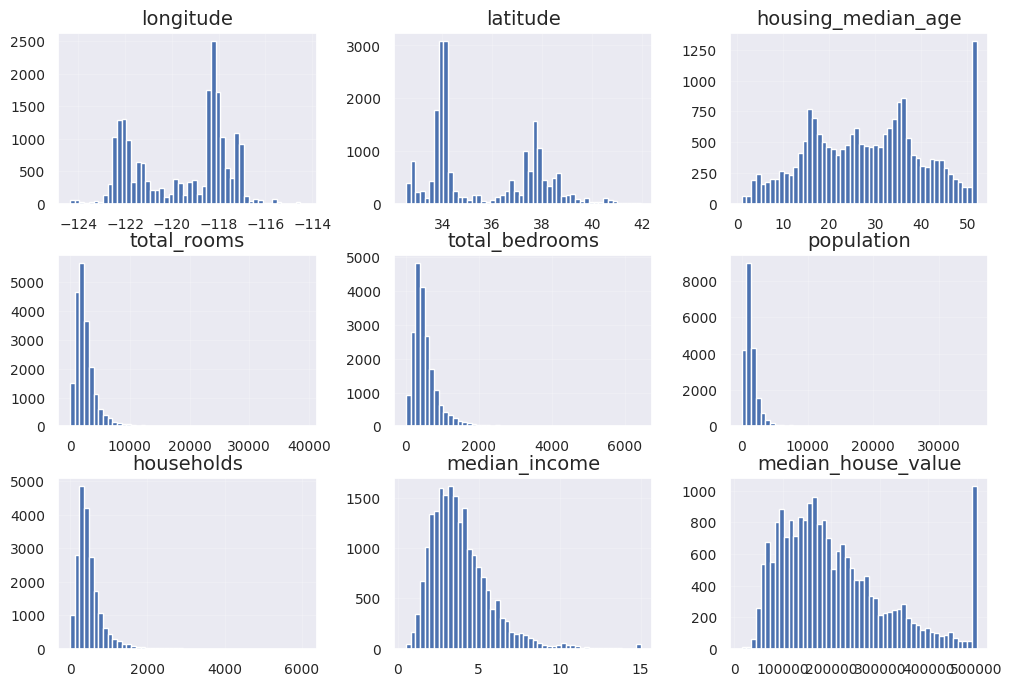

In [17]:
import matplotlib.pyplot as plt

# extra code – the next 5 lines define the default font sizes
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

housing_full.hist(bins=50, figsize=(12, 8))

plt.show()

In [18]:
import numpy as np

def shuffle_and_split_data(data, test_ratio, rng):
    shuffled_indices = rng.permutation(len(data))
    test_set_size = int(len(data) * test_ratio)
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

In [19]:
rng = np.random.default_rng(seed=42)
train_set, test_set = shuffle_and_split_data(housing_full, 0.2, rng)
len(train_set)

16512

In [20]:
len(test_set)

4128

In [21]:
from zlib import crc32

def is_id_in_test_set(identifier, test_ratio):
    return crc32(np.int64(identifier)) < test_ratio * 2**32

def split_data_with_id_hash(data, test_ratio, id_column):
    ids = data[id_column]
    in_test_set = ids.apply(lambda id_: is_id_in_test_set(id_, test_ratio))
    return data.loc[~in_test_set], data.loc[in_test_set]

In [22]:
housing_with_id = housing_full.reset_index()  # adds an `index` column
train_set, test_set = split_data_with_id_hash(housing_with_id, 0.2, "index")

In [23]:
housing_with_id["id"] = (housing_full["longitude"] * 1000
                         + housing_full["latitude"])
train_set, test_set = split_data_with_id_hash(housing_with_id, 0.2, "id")

In [24]:
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(housing_full, test_size=0.2,
                                       random_state=42)

In [25]:
# extra code – shows how to compute the 10.7% proba of getting a bad sample

from scipy.stats import binom

sample_size = 1000
ratio_female = 0.516
proba_too_small = binom(sample_size, ratio_female).cdf(490 - 1)
proba_too_large = 1 - binom(sample_size, ratio_female).cdf(540)
print(proba_too_small + proba_too_large)

0.10727422667455615


In [26]:
# extra code – shows another way to estimate the probability of bad sample

rng = np.random.default_rng(seed=42)
samples = (rng.random((100_000, sample_size)) < ratio_female).sum(axis=1)
((samples < 490) | (samples > 540)).mean()

np.float64(0.1077)

In [27]:
housing_full["income_cat"] = pd.cut(housing_full["median_income"],
                                    bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                                    labels=[1, 2, 3, 4, 5])

In [28]:
housing_full["income_cat"].value_counts().sort_index()

,count
income_cat,
1,822
2,6581
3,7236
4,3639
5,2362


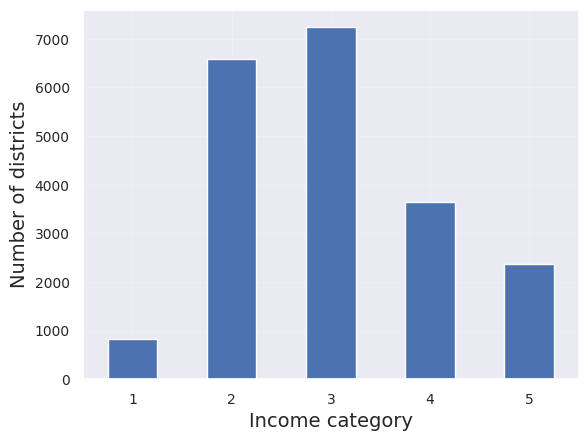

In [29]:
cat_counts = housing_full["income_cat"].value_counts().sort_index()
cat_counts.plot.bar(rot=0, grid=True)
plt.xlabel("Income category")
plt.ylabel("Number of districts")

plt.show()

In [30]:
from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits=10, test_size=0.2, random_state=42)
strat_splits = []
for train_index, test_index in splitter.split(housing_full,
                                              housing_full["income_cat"]):
    strat_train_set_n = housing_full.iloc[train_index]
    strat_test_set_n = housing_full.iloc[test_index]
    strat_splits.append([strat_train_set_n, strat_test_set_n])

In [31]:
strat_train_set, strat_test_set = strat_splits[0]

print(strat_train_set.shape)
print(strat_test_set.shape)

(16512, 11)
(4128, 11)


In [32]:
strat_train_set, strat_test_set = train_test_split(
    housing_full, test_size=0.2, stratify=housing_full["income_cat"],
    random_state=42)

In [33]:
strat_train_set["income_cat"].value_counts() / len(strat_train_set)

,count
income_cat,
3,0.350594
2,0.318859
4,0.176296
5,0.114462
1,0.039789


In [34]:
# extra code – computes the data for Figure 2–10

def income_cat_proportions(data):
    return data["income_cat"].value_counts() / len(data)

train_set, test_set = train_test_split(housing_full, test_size=0.2,
                                       random_state=42)

compare_props = pd.DataFrame({
    "Overall %": income_cat_proportions(housing_full),
    "Stratified %": income_cat_proportions(strat_test_set),
    "Random %": income_cat_proportions(test_set),
}).sort_index()
compare_props.index.name = "Income Category"
compare_props["Strat. Error %"] = (compare_props["Stratified %"] /
                                   compare_props["Overall %"] - 1)
compare_props["Rand. Error %"] = (compare_props["Random %"] /
                                  compare_props["Overall %"] - 1)
(compare_props * 100).round(2)

,Overall %,Stratified %,Random %,Strat. Error %,Rand. Error %
Income Category,,,,,
1,3.98,4.00,4.24,0.36,6.45
2,31.88,31.88,30.74,-0.02,-3.59
3,35.06,35.05,34.52,-0.01,-1.53
4,17.63,17.64,18.41,0.03,4.42
5,11.44,11.43,12.09,-0.08,5.63


In [35]:
for set_ in (strat_train_set, strat_test_set):
    set_.drop("income_cat", axis=1, inplace=True)

In [36]:
housing = strat_train_set.copy()

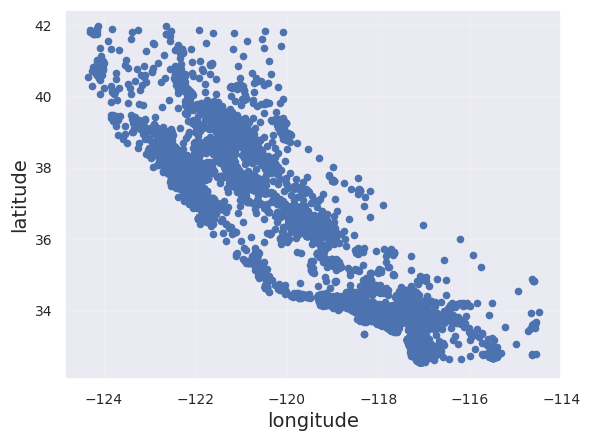

In [37]:
housing.plot(kind="scatter", x="longitude", y="latitude", grid=True)

plt.show()

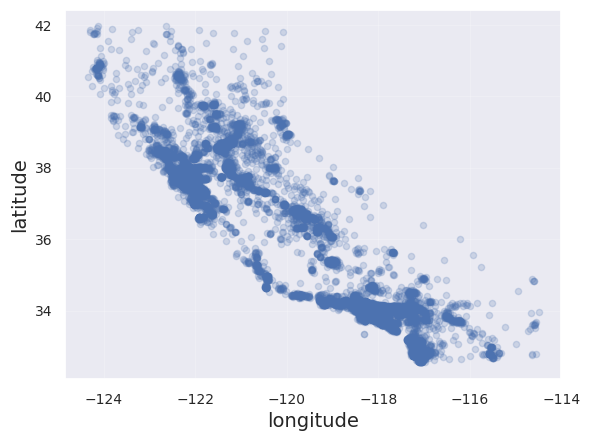

In [38]:
housing.plot(kind="scatter", x="longitude", y="latitude", grid=True, alpha=0.2)

plt.show()

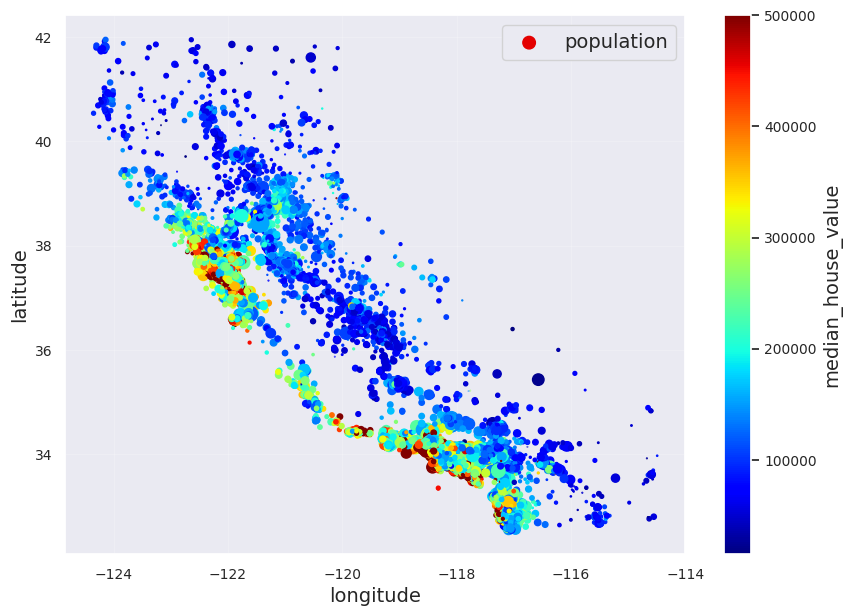

In [39]:
housing.plot(kind="scatter", x="longitude", y="latitude", grid=True,
            s=housing["population"] / 100, label="population",
            c="median_house_value", cmap="jet", colorbar=True,
            legend=True, sharex=False, figsize=(10, 7))

plt.show()

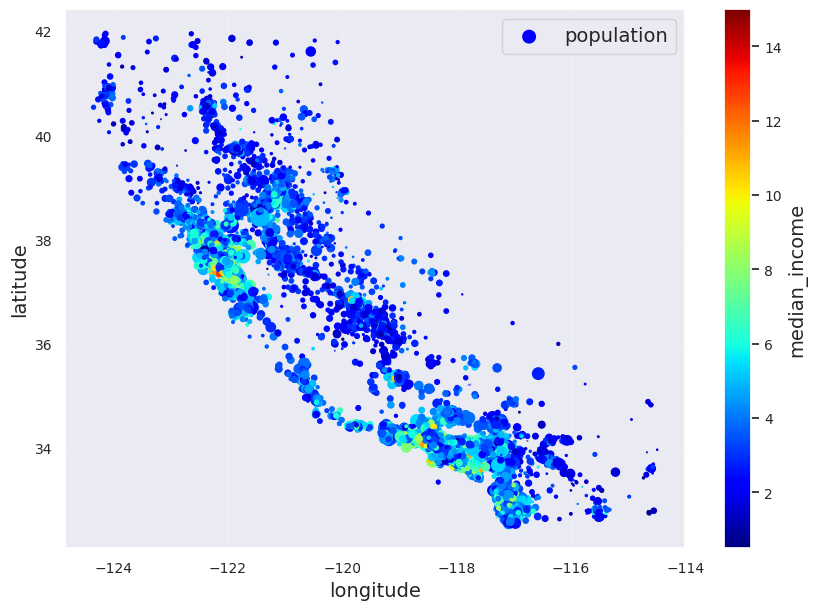

In [40]:
housing.plot(kind="scatter", x="longitude", y="latitude", grid=True,
            s=housing["population"] / 100, label="population",
            c="median_income", cmap="jet", colorbar=True,
            legend=True, sharex=False, figsize=(10, 7))

plt.show()

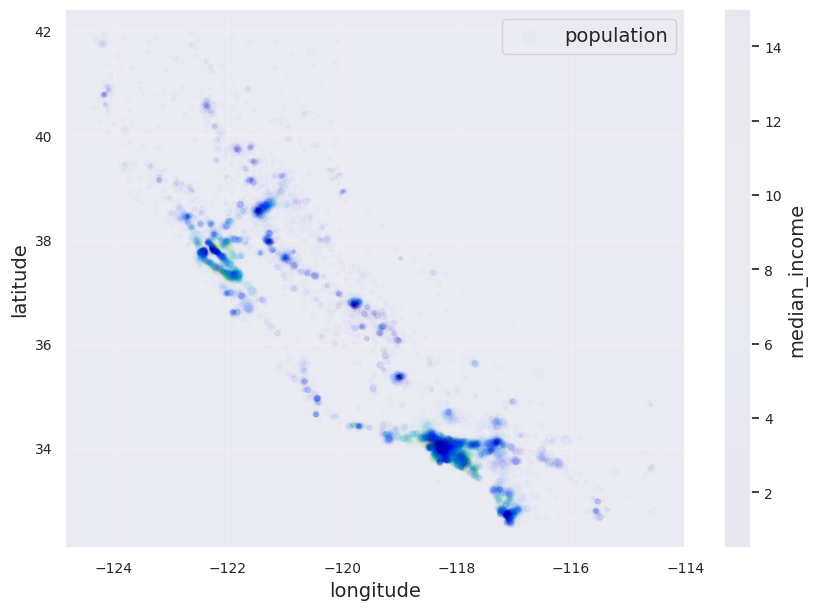

In [41]:
housing.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    grid=True,
    s=housing["population"] / 100,
    label="population",
    c="median_income",
    cmap="jet",
    alpha=0.01,  # Transparency
    colorbar=True,
    legend=True,
    sharex=False,
    figsize=(10, 7)
)

plt.show()

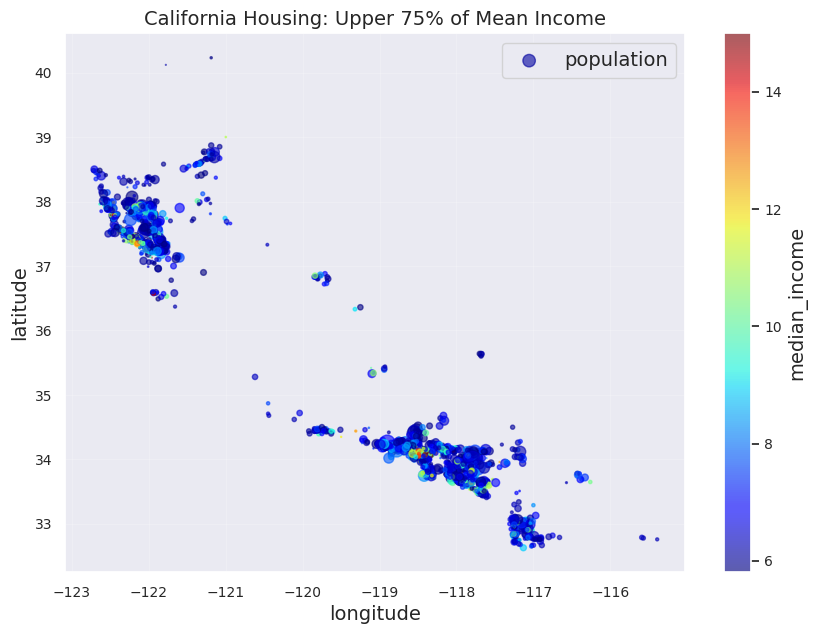

In [42]:

import matplotlib.pyplot as plt

# Find the median income threshold (50th percentile)
income_threshold = housing["median_income"].mean()

# Keep only the upper 50% of income values
high_income = housing[
    housing["median_income"] >= 1.5*income_threshold
]

# Plot higher-income districts
high_income.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    grid=True,
    s=high_income["population"] / 100,
    label="population",
    c="median_income",
    cmap="jet",
    alpha=0.6,
    colorbar=True,
    legend=True,
    sharex=False,
    figsize=(10, 7)
)

plt.title("California Housing: Upper 75% of Mean Income")
plt.show()


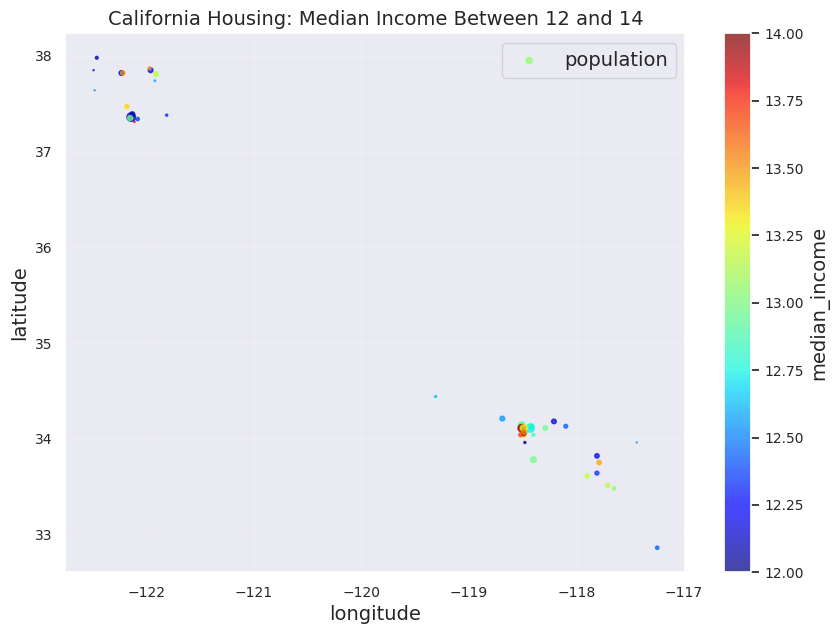

Number of districts: 45


In [43]:

import matplotlib.pyplot as plt

# Filter districts with median_income between 12 and 14
income_12_14 = housing[
    housing["median_income"].between(12, 14)
]

# Plot selected districts
income_12_14.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    grid=True,
    s=income_12_14["population"] / 100,
    label="population",
    c="median_income",
    cmap="jet",
    vmin=12,
    vmax=14,
    alpha=0.7,
    colorbar=True,
    legend=True,
    sharex=False,
    figsize=(10, 7)
)

plt.title("California Housing: Median Income Between 12 and 14")
plt.show()

print("Number of districts:", len(income_12_14))


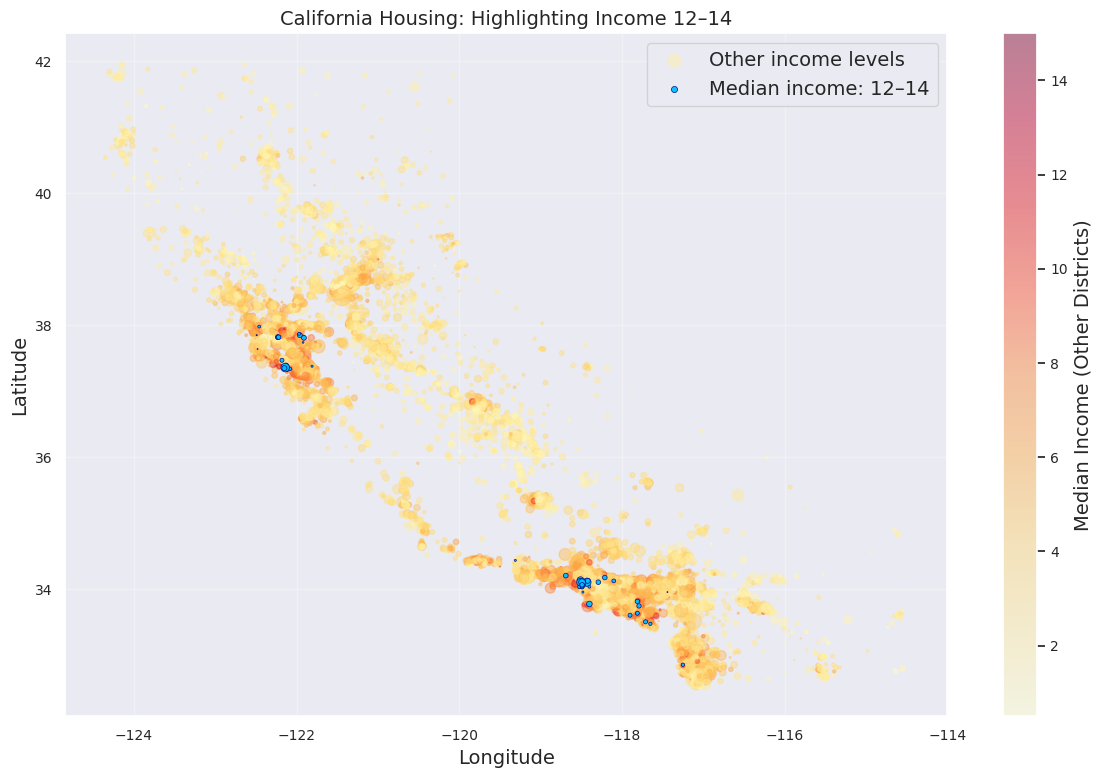

Districts with median income 12–14: 45


In [44]:

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# Identify the target income range
target = housing["median_income"].between(12, 14)
other = housing[~target]
selected = housing[target]

fig, ax = plt.subplots(figsize=(12, 8))

# Warm colours for all other income values
scatter = ax.scatter(
    other["longitude"],
    other["latitude"],
    s=other["population"] / 100,
    c=other["median_income"],
    cmap="YlOrRd",
    norm=mcolors.Normalize(
        vmin=housing["median_income"].min(),
        vmax=housing["median_income"].max()
    ),
    alpha=0.45,
    label="Other income levels"
)

# Distinct cold blue for income between 12 and 14
ax.scatter(
    selected["longitude"],
    selected["latitude"],
    s=selected["population"] / 100,
    color="deepskyblue",
    edgecolors="navy",
    linewidths=0.5,
    alpha=0.95,
    label="Median income: 12–14"
)

# Add colour scale for other incomes
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Median Income (Other Districts)")

ax.set_title("California Housing: Highlighting Income 12–14")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

print(f"Districts with median income 12–14: {target.sum():,}")


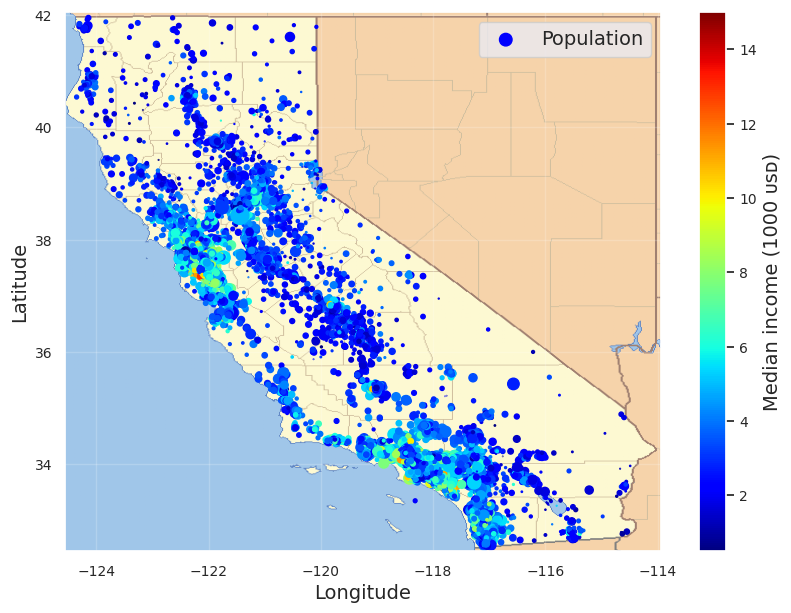

In [45]:
# extra code – this cell generates the first figure in the chapter

# Download the California image
filename = "california.png"
filepath = Path(f"my_{filename}")
if not filepath.is_file():
    homlp_root = "https://github.com/ageron/handson-mlp/raw/main/"
    url = homlp_root + "images/end_to_end_project/" + filename
    print("Downloading", filename)
    urllib.request.urlretrieve(url, filepath)

housing_renamed = housing.rename(columns={
    "latitude": "Latitude", "longitude": "Longitude",
    "population": "Population",
    "median_income": "Median income (1000 ᴜsᴅ)"})
housing_renamed.plot(
             kind="scatter", x="Longitude", y="Latitude",
             s=housing_renamed["Population"] / 100, label="Population",
             c="Median income (1000 ᴜsᴅ)", cmap="jet", colorbar=True,
             legend=True, sharex=False, figsize=(10, 7))

california_img = plt.imread(filepath)
axis = -124.55, -113.95, 32.45, 42.05
plt.axis(axis)
plt.imshow(california_img, extent=axis)

plt.show()

In [46]:
corr_matrix = housing.corr(numeric_only=True)

In [47]:
corr_matrix["median_income"].sort_values(ascending=False)

,median_income
median_income,1.000000
median_house_value,0.688380
total_rooms,0.197720
households,0.013637
population,0.004282
total_bedrooms,-0.006038
longitude,-0.016542
latitude,-0.078137
housing_median_age,-0.127043


In [48]:
corr_matrix["median_house_value"].sort_values(ascending=False)

,median_house_value
median_house_value,1.000000
median_income,0.688380
total_rooms,0.137455
housing_median_age,0.102175
households,0.071426
total_bedrooms,0.054635
population,-0.020153
longitude,-0.050859
latitude,-0.139584


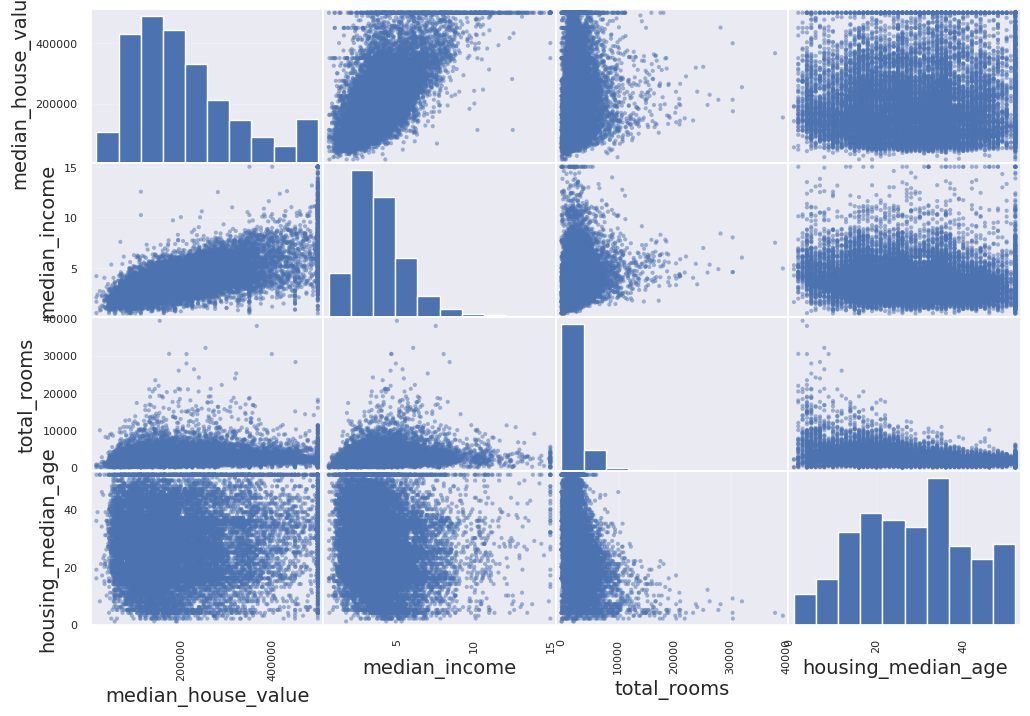

In [49]:
from pandas.plotting import scatter_matrix

attributes = ["median_house_value", "median_income", "total_rooms",
              "housing_median_age"]
scatter_matrix(housing[attributes], figsize=(12, 8))

plt.show()

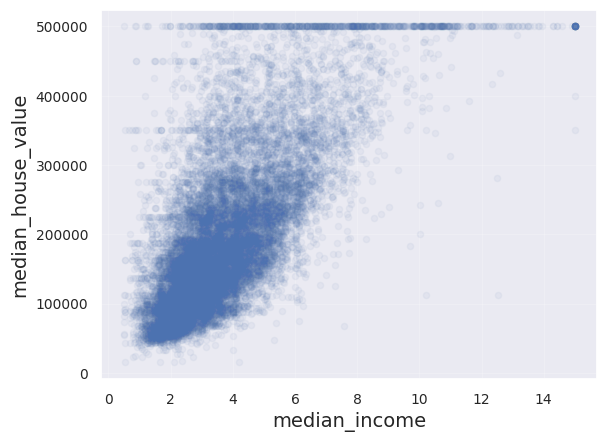

In [50]:
housing.plot(kind="scatter", x="median_income", y="median_house_value",
             alpha=0.05, grid=True)

plt.show()

In [51]:
housing["rooms_per_house"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_ratio"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["people_per_house"] = housing["population"] / housing["households"]

In [52]:
housing.head(30)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_house,bedrooms_ratio,people_per_house
13096,-122.42,37.80,52.0,3321.0,1115.0,1576.0,1034.0,2.0987,458300.0,NEAR BAY,3.211799,0.335742,1.524178
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876,483800.0,<1H OCEAN,5.504202,0.180153,1.865546
3785,-121.98,38.36,33.0,1083.0,217.0,562.0,203.0,2.4330,101700.0,INLAND,5.334975,0.200369,2.768473
14689,-117.11,33.75,17.0,4174.0,851.0,1845.0,780.0,2.2618,96100.0,INLAND,5.351282,0.203881,2.365385
20507,-118.15,33.77,36.0,4366.0,1211.0,1912.0,1172.0,3.5292,361800.0,NEAR OCEAN,3.725256,0.277371,1.631399
1286,-121.31,37.96,52.0,1829.0,301.0,694.0,319.0,3.3466,92600.0,INLAND,5.733542,0.164571,2.175549
18078,-118.36,33.85,34.0,1086.0,197.0,509.0,158.0,6.1133,349300.0,<1H OCEAN,6.873418,0.181400,3.221519
4396,-122.13,37.41,36.0,4787.0,900.0,2039.0,890.0,5.4063,440900.0,NEAR BAY,5.378652,0.188009,2.291011
18031,-118.44,34.31,22.0,3182.0,822.0,2661.0,746.0,2.7472,160100.0,<1H OCEAN,4.265416,0.258328,3.567024
6753,-118.13,34.06,17.0,1714.0,572.0,1590.0,568.0,1.1875,183900.0,<1H OCEAN,3.017606,0.333722,2.799296


In [53]:
corr_matrix = housing.corr(numeric_only=True)
corr_matrix["median_house_value"].sort_values(ascending=False)

,median_house_value
median_house_value,1.000000
median_income,0.688380
rooms_per_house,0.143663
total_rooms,0.137455
housing_median_age,0.102175
households,0.071426
total_bedrooms,0.054635
population,-0.020153
people_per_house,-0.038224
longitude,-0.050859


In [54]:
housing = strat_train_set.drop("median_house_value", axis=1)
housing_labels = strat_train_set["median_house_value"].copy()

In [55]:
#housing.dropna(subset=["total_bedrooms"], inplace=True)    # option 1

#housing.drop("total_bedrooms", axis=1, inplace=True)       # option 2

#median = housing["total_bedrooms"].median()  # option 3
#housing["total_bedrooms"] = housing["total_bedrooms"].fillna(median)

In [56]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

In [57]:
housing_num = housing.select_dtypes(include=[np.number])

In [58]:
imputer.fit(housing_num)

SimpleImputer(strategy='median')

In [59]:
imputer.statistics_

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

In [60]:
housing_num.median().values

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

In [61]:
X = imputer.transform(housing_num)

In [62]:
imputer.feature_names_in_

array(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income'],
      dtype=object)

In [63]:
housing_tr = pd.DataFrame(X, columns=housing_num.columns,
                          index=housing_num.index)

In [64]:
housing_tr.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
13096,-122.42,37.80,52.0,3321.0,1115.0,1576.0,1034.0,2.0987
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876
3785,-121.98,38.36,33.0,1083.0,217.0,562.0,203.0,2.4330
14689,-117.11,33.75,17.0,4174.0,851.0,1845.0,780.0,2.2618
20507,-118.15,33.77,36.0,4366.0,1211.0,1912.0,1172.0,3.5292


In [65]:
housing_cat = housing[["ocean_proximity"]]
housing_cat.head(8)

,ocean_proximity
13096,NEAR BAY
14973,<1H OCEAN
3785,INLAND
14689,INLAND
20507,NEAR OCEAN
1286,INLAND
18078,<1H OCEAN
4396,NEAR BAY


In [66]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_encoder = OrdinalEncoder()
housing_cat_encoded = ordinal_encoder.fit_transform(housing_cat)

In [67]:
housing_cat_encoded[:8]

array([[3.],
       [0.],
       [1.],
       [1.],
       [4.],
       [1.],
       [0.],
       [3.]])

In [68]:
ordinal_encoder.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

In [69]:
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder()
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)

In [70]:
housing_cat_1hot

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 16512 stored elements and shape (16512, 5)>

In [71]:
housing_cat_1hot.toarray()

array([[0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.]])

In [72]:
cat_encoder = OneHotEncoder(sparse_output=False)
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)
housing_cat_1hot

array([[0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.]])

In [73]:
cat_encoder.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

In [74]:
df_test = pd.DataFrame({"ocean_proximity": ["INLAND", "NEAR BAY", "<1H OCEAN"]})
pd.get_dummies(df_test)

,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_NEAR BAY
0,False,True,False
1,False,False,True
2,True,False,False


In [75]:
cat_encoder.transform(df_test)

array([[0., 1., 0., 0., 0.],
       [0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.]])

In [76]:
df_test_unknown = pd.DataFrame({"ocean_proximity": ["<2H OCEAN", "ISLAND"]})
pd.get_dummies(df_test_unknown)

,ocean_proximity_<2H OCEAN,ocean_proximity_ISLAND
0,True,False
1,False,True


In [77]:
cat_encoder.handle_unknown = "ignore"
cat_encoder.transform(df_test_unknown)

array([[0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0.]])

In [78]:
cat_encoder.feature_names_in_

array(['ocean_proximity'], dtype=object)

In [79]:
cat_encoder.get_feature_names_out()

array(['ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND',
       'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY',
       'ocean_proximity_NEAR OCEAN'], dtype=object)

In [80]:
df_output = pd.DataFrame(cat_encoder.transform(df_test_unknown),
                         columns=cat_encoder.get_feature_names_out(),
                         index=df_test_unknown.index)

In [81]:
df_output

,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0


In [82]:
from sklearn.preprocessing import MinMaxScaler

min_max_scaler = MinMaxScaler(feature_range=(-1, 1))
housing_num_min_max_scaled = min_max_scaler.fit_transform(housing_num)

In [83]:
from sklearn.preprocessing import StandardScaler

std_scaler = StandardScaler()
housing_num_std_scaled = std_scaler.fit_transform(housing_num)

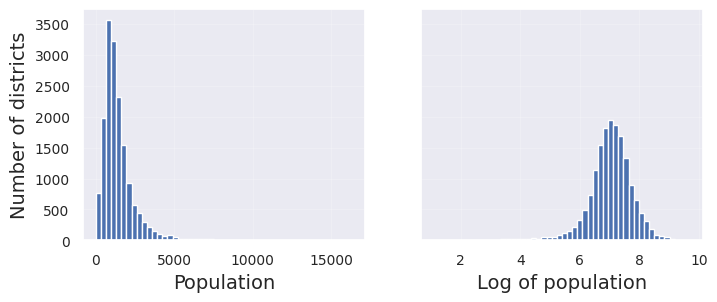

In [84]:
# extra code – this cell generates Figure 2–17
fig, axs = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
housing["population"].hist(ax=axs[0], bins=50)
housing["population"].apply(np.log).hist(ax=axs[1], bins=50)
axs[0].set_xlabel("Population")
axs[1].set_xlabel("Log of population")
axs[0].set_ylabel("Number of districts")

plt.show()

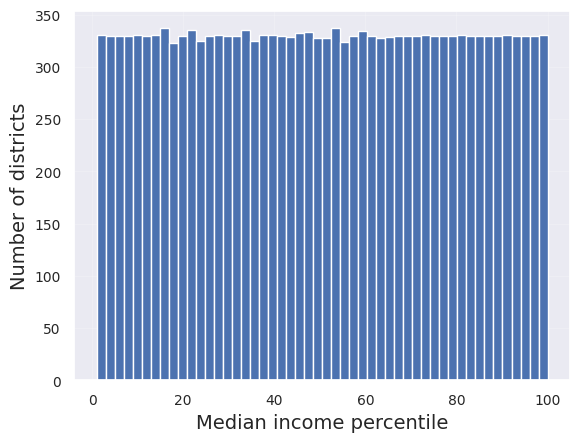

In [85]:
# extra code – just shows that we get a uniform distribution
percentiles = [np.percentile(housing["median_income"], p)
               for p in range(1, 100)]
flattened_median_income = pd.cut(housing["median_income"],
                                 bins=[-np.inf] + percentiles + [np.inf],
                                 labels=range(1, 100 + 1))
flattened_median_income.hist(bins=50)
plt.xlabel("Median income percentile")
plt.ylabel("Number of districts")
plt.show()
# Note: incomes below the 1st percentile are labeled 1, and incomes above the
# 99th percentile are labeled 100. This is why the distribution below ranges
# from 1 to 100 (not 0 to 100).

In [86]:
from sklearn.metrics.pairwise import rbf_kernel

age_simil_35 = rbf_kernel(housing[["housing_median_age"]], [[35]], gamma=0.1)

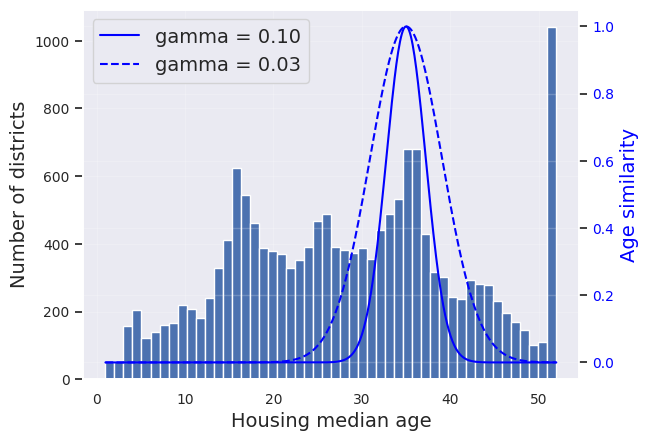

In [87]:
# extra code – this cell generates Figure 2–18

ages = np.linspace(housing["housing_median_age"].min(),
                   housing["housing_median_age"].max(),
                   500).reshape(-1, 1)
gamma1 = 0.1
gamma2 = 0.03
rbf1 = rbf_kernel(ages, [[35]], gamma=gamma1)
rbf2 = rbf_kernel(ages, [[35]], gamma=gamma2)

fig, ax1 = plt.subplots()

ax1.set_xlabel("Housing median age")
ax1.set_ylabel("Number of districts")
ax1.hist(housing["housing_median_age"], bins=50)

ax2 = ax1.twinx()  # create a twin axis that shares the same x-axis
color = "blue"
ax2.plot(ages, rbf1, color=color, label="gamma = 0.10")
ax2.plot(ages, rbf2, color=color, label="gamma = 0.03", linestyle="--")
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylabel("Age similarity", color=color)

plt.legend(loc="upper left")

plt.show()

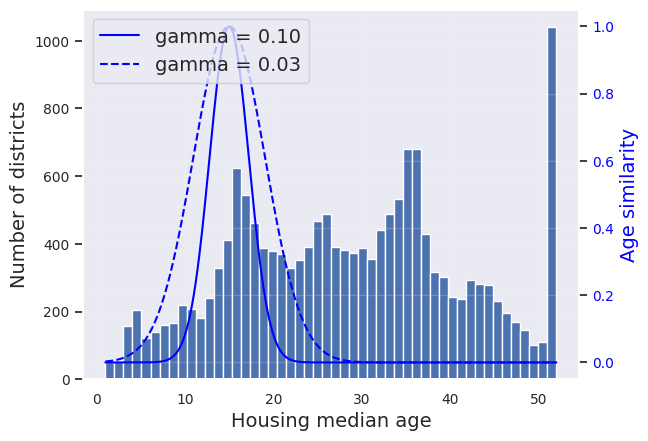

In [88]:
# extra code – this cell generates Figure 2–18

ages = np.linspace(housing["housing_median_age"].min(),
                   housing["housing_median_age"].max(),
                   500).reshape(-1, 1)
gamma1 = 0.1
gamma2 = 0.03
rbf1 = rbf_kernel(ages, [[15]], gamma=gamma1)
rbf2 = rbf_kernel(ages, [[15]], gamma=gamma2)

fig, ax1 = plt.subplots()

ax1.set_xlabel("Housing median age")
ax1.set_ylabel("Number of districts")
ax1.hist(housing["housing_median_age"], bins=50)

ax2 = ax1.twinx()  # create a twin axis that shares the same x-axis
color = "blue"
ax2.plot(ages, rbf1, color=color, label="gamma = 0.10")
ax2.plot(ages, rbf2, color=color, label="gamma = 0.03", linestyle="--")
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylabel("Age similarity", color=color)

plt.legend(loc="upper left")

plt.show()

In [89]:
from sklearn.linear_model import LinearRegression

target_scaler = StandardScaler()
scaled_labels = target_scaler.fit_transform(housing_labels.to_frame())

model = LinearRegression()
model.fit(housing[["median_income"]], scaled_labels)
some_new_data = housing[["median_income"]].iloc[:5]  # pretend this is new data

scaled_predictions = model.predict(some_new_data)
predictions = target_scaler.inverse_transform(scaled_predictions)

In [90]:
predictions

array([[131997.15275877],
       [299359.35844434],
       [146023.37185694],
       [138840.33653057],
       [192016.61557639]])

In [91]:
from sklearn.compose import TransformedTargetRegressor

model = TransformedTargetRegressor(LinearRegression(),
                                   transformer=StandardScaler())
model.fit(housing[["median_income"]], housing_labels)
predictions = model.predict(some_new_data)

In [92]:
predictions

array([131997.15275877, 299359.35844434, 146023.37185694, 138840.33653057,
       192016.61557639])

In [93]:
from sklearn.preprocessing import FunctionTransformer

log_transformer = FunctionTransformer(np.log, inverse_func=np.exp)
log_pop = log_transformer.transform(housing[["population"]])

In [94]:
rbf_transformer = FunctionTransformer(rbf_kernel,
                                      kw_args=dict(Y=[[35.]], gamma=0.1))
age_simil_35 = rbf_transformer.transform(housing[["housing_median_age"]])

In [95]:
age_simil_35

array([[2.81118530e-13],
       [8.20849986e-02],
       [6.70320046e-01],
       ...,
       [9.55316054e-22],
       [6.70320046e-01],
       [3.03539138e-04]])

In [96]:
sf_coords = 37.7749, -122.41
sf_transformer = FunctionTransformer(rbf_kernel,
                                     kw_args=dict(Y=[sf_coords], gamma=0.1))
sf_simil = sf_transformer.transform(housing[["latitude", "longitude"]])

In [97]:
sf_simil

array([[0.999927  ],
       [0.05258419],
       [0.94864161],
       ...,
       [0.00388525],
       [0.05038518],
       [0.99868067]])

In [98]:
ratio_transformer = FunctionTransformer(lambda X: X[:, [0]] / X[:, [1]])
ratio_transformer.transform(np.array([[1., 2.], [3., 4.]]))

array([[0.5 ],
       [0.75]])

In [99]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_array, check_is_fitted

class StandardScalerClone(BaseEstimator, TransformerMixin):
    def __init__(self, with_mean=True):  # no *args or **kwargs!
        self.with_mean = with_mean

    def fit(self, X, y=None):  # y is required even though we don't use it
        X = check_array(X)  # checks that X is an array with finite float values
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)
        self.scale_[self.scale_ == 0] = 1  # Avoid division by zero for constant features
        self.n_features_in_ = X.shape[1]  # every estimator stores this in fit()
        return self  # always return self!

    def transform(self, X):
        check_is_fitted(self)  # looks for learned attributes (with trailing _)
        X = check_array(X)
        assert self.n_features_in_ == X.shape[1]
        if self.with_mean:
            X = X - self.mean_
        return X / self.scale_

In [100]:
from sklearn.cluster import KMeans

class ClusterSimilarity(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=10, gamma=1.0, random_state=None):
        self.n_clusters = n_clusters
        self.gamma = gamma
        self.random_state = random_state

    def fit(self, X, y=None, sample_weight=None):
        self.kmeans_ = KMeans(self.n_clusters, random_state=self.random_state)
        self.kmeans_.fit(X, sample_weight=sample_weight)
        return self  # always return self!

    def transform(self, X):
        return rbf_kernel(X, self.kmeans_.cluster_centers_, gamma=self.gamma)

    def get_feature_names_out(self, names=None):
        return [f"Cluster {i} similarity" for i in range(self.n_clusters)]

In [101]:
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
13096,-122.42,37.80,52.0,3321.0,1115.0,1576.0,1034.0,2.0987,NEAR BAY
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876,<1H OCEAN
3785,-121.98,38.36,33.0,1083.0,217.0,562.0,203.0,2.4330,INLAND
14689,-117.11,33.75,17.0,4174.0,851.0,1845.0,780.0,2.2618,INLAND
20507,-118.15,33.77,36.0,4366.0,1211.0,1912.0,1172.0,3.5292,NEAR OCEAN


In [102]:
cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1., random_state=42)
similarities = cluster_simil.fit_transform(housing[["latitude", "longitude"]])

In [103]:
#cluster_simil = ClusterSimilarity(n_clusters=3, gamma=1., random_state=42)
#similarities = cluster_simil.fit_transform(housing[["latitude", "longitude"]], sample_weight=housing["housing_median_age"])

In [104]:
similarities[:3].round(2)

array([[0.46, 0.  , 0.08, 0.  , 0.  , 0.  , 0.  , 0.98, 0.  , 0.  ],
       [0.  , 0.96, 0.  , 0.03, 0.04, 0.  , 0.  , 0.  , 0.11, 0.35],
       [0.34, 0.  , 0.45, 0.  , 0.  , 0.  , 0.01, 0.73, 0.  , 0.  ]])

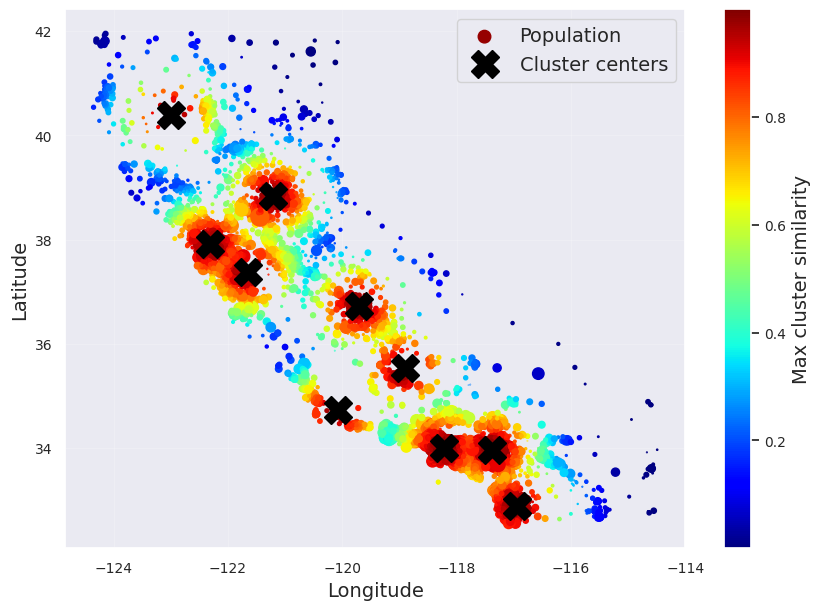

In [105]:
# extra code – this cell generates Figure 2–19

housing_renamed = housing.rename(columns={
    "latitude": "Latitude", "longitude": "Longitude",
    "population": "Population",
    "median_house_value": "Median house value (ᴜsᴅ)"})
housing_renamed["Max cluster similarity"] = similarities.max(axis=1)

housing_renamed.plot(kind="scatter", x="Longitude", y="Latitude", grid=True,
                     s=housing_renamed["Population"] / 100, label="Population",
                     c="Max cluster similarity",
                     cmap="jet", colorbar=True,
                     legend=True, sharex=False, figsize=(10, 7))
plt.plot(cluster_simil.kmeans_.cluster_centers_[:, 1],
         cluster_simil.kmeans_.cluster_centers_[:, 0],
         linestyle="", color="black", marker="X", markersize=20,
         label="Cluster centers")
plt.legend(loc="upper right")

plt.show()

In [106]:
from sklearn.pipeline import Pipeline

num_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("standardize", StandardScaler()),
])

In [107]:
from sklearn.pipeline import make_pipeline

num_pipeline = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())

In [108]:
from sklearn import set_config

set_config(display='diagram')

num_pipeline

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler())])

In [109]:
housing_num_prepared = num_pipeline.fit_transform(housing_num)
housing_num_prepared[:2].round(2)

array([[-1.42,  1.01,  1.86,  0.31,  1.37,  0.14,  1.39, -0.94],
       [ 0.6 , -0.7 ,  0.91, -0.31, -0.44, -0.69, -0.37,  1.17]])

In [110]:
df_housing_num_prepared = pd.DataFrame(
    housing_num_prepared, columns=num_pipeline.get_feature_names_out(),
    index=housing_num.index)

In [111]:
df_housing_num_prepared.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
13096,-1.423037,1.013606,1.861119,0.311912,1.368167,0.137460,1.394812,-0.936491
14973,0.596394,-0.702103,0.907630,-0.308620,-0.435925,-0.693771,-0.373485,1.171942
3785,-1.203098,1.276119,0.351428,-0.712240,-0.760709,-0.788768,-0.775727,-0.759789
14689,1.231216,-0.884924,-0.919891,0.702262,0.742306,0.383175,0.731375,-0.850281
20507,0.711362,-0.875549,0.589800,0.790125,1.595753,0.444376,1.755263,-0.180365


In [112]:
num_pipeline.steps

[('simpleimputer', SimpleImputer(strategy='median')),
 ('standardscaler', StandardScaler())]

In [113]:
num_pipeline[1]

StandardScaler()

In [114]:
num_pipeline[:-1]

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median'))])

In [115]:
num_pipeline.named_steps["simpleimputer"]

SimpleImputer(strategy='median')

In [116]:
num_pipeline.set_params(simpleimputer__strategy="median")

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler())])

In [117]:
from sklearn.compose import ColumnTransformer

num_attribs = ["longitude", "latitude", "housing_median_age", "total_rooms",
               "total_bedrooms", "population", "households", "median_income"]
cat_attribs = ["ocean_proximity"]

cat_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore"))

preprocessing = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
    ("cat", cat_pipeline, cat_attribs),
])

In [118]:
from sklearn.compose import make_column_selector, make_column_transformer

preprocessing = make_column_transformer(
    (num_pipeline, make_column_selector(dtype_include=np.number)),
    (cat_pipeline, make_column_selector(dtype_include=object)),
)

In [119]:
housing_prepared = preprocessing.fit_transform(housing)

In [120]:
# extra code – shows that we can get a DataFrame out if we want
housing_prepared_fr = pd.DataFrame(
    housing_prepared,
    columns=preprocessing.get_feature_names_out(),
    index=housing.index)
housing_prepared_fr.head()

,pipeline-1__longitude,pipeline-1__latitude,pipeline-1__housing_median_age,pipeline-1__total_rooms,pipeline-1__total_bedrooms,pipeline-1__population,pipeline-1__households,pipeline-1__median_income,pipeline-2__ocean_proximity_<1H OCEAN,pipeline-2__ocean_proximity_INLAND,pipeline-2__ocean_proximity_ISLAND,pipeline-2__ocean_proximity_NEAR BAY,pipeline-2__ocean_proximity_NEAR OCEAN
13096,-1.423037,1.013606,1.861119,0.311912,1.368167,0.137460,1.394812,-0.936491,0.0,0.0,0.0,1.0,0.0
14973,0.596394,-0.702103,0.907630,-0.308620,-0.435925,-0.693771,-0.373485,1.171942,1.0,0.0,0.0,0.0,0.0
3785,-1.203098,1.276119,0.351428,-0.712240,-0.760709,-0.788768,-0.775727,-0.759789,0.0,1.0,0.0,0.0,0.0
14689,1.231216,-0.884924,-0.919891,0.702262,0.742306,0.383175,0.731375,-0.850281,0.0,1.0,0.0,0.0,0.0
20507,0.711362,-0.875549,0.589800,0.790125,1.595753,0.444376,1.755263,-0.180365,0.0,0.0,0.0,0.0,1.0


In [121]:
def column_ratio(X):
    return X[:, [0]] / X[:, [1]]

def ratio_name(function_transformer, feature_names_in):
    return ["ratio"]  # feature names out

def ratio_pipeline():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        FunctionTransformer(column_ratio, feature_names_out=ratio_name),
        StandardScaler())

log_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    FunctionTransformer(np.log, feature_names_out="one-to-one"),
    StandardScaler())
cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1., random_state=42)
default_num_pipeline = make_pipeline(SimpleImputer(strategy="median"),
                                     StandardScaler())
preprocessing = ColumnTransformer([
        ("bedrooms", ratio_pipeline(), ["total_bedrooms", "total_rooms"]),
        ("rooms_per_house", ratio_pipeline(), ["total_rooms", "households"]),
        ("people_per_house", ratio_pipeline(), ["population", "households"]),
        ("log", log_pipeline, ["total_bedrooms", "total_rooms", "population",
                               "households", "median_income"]),
        ("geo", cluster_simil, ["latitude", "longitude"]),
        ("cat", cat_pipeline, make_column_selector(dtype_include=object)),
    ],
    remainder=default_num_pipeline)  # one column remaining: housing_median_age

In [122]:
housing_prepared = preprocessing.fit_transform(housing)
housing_prepared.shape

(16512, 24)

In [123]:
preprocessing.get_feature_names_out()

array(['bedrooms__ratio', 'rooms_per_house__ratio',
       'people_per_house__ratio', 'log__total_bedrooms',
       'log__total_rooms', 'log__population', 'log__households',
       'log__median_income', 'geo__Cluster 0 similarity',
       'geo__Cluster 1 similarity', 'geo__Cluster 2 similarity',
       'geo__Cluster 3 similarity', 'geo__Cluster 4 similarity',
       'geo__Cluster 5 similarity', 'geo__Cluster 6 similarity',
       'geo__Cluster 7 similarity', 'geo__Cluster 8 similarity',
       'geo__Cluster 9 similarity', 'cat__ocean_proximity_<1H OCEAN',
       'cat__ocean_proximity_INLAND', 'cat__ocean_proximity_ISLAND',
       'cat__ocean_proximity_NEAR BAY', 'cat__ocean_proximity_NEAR OCEAN',
       'remainder__housing_median_age'], dtype=object)

In [124]:
from sklearn.linear_model import LinearRegression

lin_reg = make_pipeline(preprocessing, LinearRegression())
lin_reg.fit(housing, housing_labels)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                              SimpleImputer(strategy='median')),
                                                             ('standardscaler',
                                                              StandardScaler())]),
                                   transformers=[('bedrooms',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(feature_names_out=<function ratio_name at 0x7a4...
                                                   'median_income']),
                                                 ('geo',
                                                  ClusterSimilarity(random_state=42),
                                                  ['latitude', 'longitude']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7a4cad937ed0>)])),
                ('linearregression', LinearRegression())])

In [125]:
housing_predictions = lin_reg.predict(housing)
housing_predictions[:5].round(-2)  # -2 = rounded to the nearest hundred

array([246000., 372700., 135700.,  91400., 330900.])

In [126]:
housing_labels.iloc[:5].values

array([458300., 483800., 101700.,  96100., 361800.])

In [127]:
# extra code – computes the error ratios discussed in the book
error_ratios = housing_predictions[:5].round(-2) / housing_labels.iloc[:5].values - 1
print(", ".join([f"{100 * ratio:.1f}%" for ratio in error_ratios]))

-46.3%, -23.0%, 33.4%, -4.9%, -8.5%


In [128]:
from sklearn.metrics import root_mean_squared_error

lin_rmse = root_mean_squared_error(housing_labels, housing_predictions)
lin_rmse

68972.88910758484

In [129]:
from sklearn.tree import DecisionTreeRegressor

tree_reg = make_pipeline(preprocessing, DecisionTreeRegressor(random_state=42))
tree_reg.fit(housing, housing_labels)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                              SimpleImputer(strategy='median')),
                                                             ('standardscaler',
                                                              StandardScaler())]),
                                   transformers=[('bedrooms',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(feature_names_out=<function ratio_name at 0x7a4...
                                                  ClusterSimilarity(random_state=42),
                                                  ['latitude', 'longitude']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7a4cad937ed0>)])),
                ('decisiontreeregressor',
                 DecisionTreeRegressor(random_state=42))])

In [130]:
housing_predictions = tree_reg.predict(housing)
tree_rmse = root_mean_squared_error(housing_labels, housing_predictions)
tree_rmse

0.0

In [131]:
from sklearn.model_selection import cross_val_score

tree_rmses = -cross_val_score(tree_reg, housing, housing_labels,
                              scoring="neg_root_mean_squared_error", cv=10)

In [132]:
pd.Series(tree_rmses).describe()

,0
count,10.000000
mean,66573.734600
std,1103.402323
min,64607.896046
25%,66204.731788
50%,66388.272499
75%,66826.257468
max,68532.210664


In [133]:
# extra code – computes the error stats for the linear model
lin_rmses = -cross_val_score(lin_reg, housing, housing_labels,
                              scoring="neg_root_mean_squared_error", cv=10)
pd.Series(lin_rmses).describe()

,0
count,10.000000
mean,70003.404818
std,4182.188328
min,65504.765753
25%,68172.065831
50%,68743.995249
75%,70344.943988
max,81037.863741


In [134]:
from sklearn.ensemble import RandomForestRegressor

forest_reg = make_pipeline(preprocessing,
                           RandomForestRegressor(random_state=42))
forest_rmses = -cross_val_score(forest_reg, housing, housing_labels,
                                scoring="neg_root_mean_squared_error", cv=10)

In [135]:
pd.Series(forest_rmses).describe()

,0
count,10.000000
mean,47038.092799
std,1021.491757
min,45495.976649
25%,46510.418013
50%,47118.719249
75%,47480.519175
max,49140.832210


In [136]:
forest_reg.fit(housing, housing_labels)
housing_predictions = forest_reg.predict(housing)
forest_rmse = root_mean_squared_error(housing_labels, housing_predictions)
forest_rmse

17551.2122500877

In [137]:
from sklearn.model_selection import GridSearchCV

full_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("random_forest", RandomForestRegressor(random_state=42)),
])
param_grid = [
    {'preprocessing__geo__n_clusters': [5, 8, 10],
     'random_forest__max_features': [4, 6, 8]},
    {'preprocessing__geo__n_clusters': [10, 15],
     'random_forest__max_features': [6, 8, 10]},
]
grid_search = GridSearchCV(full_pipeline, param_grid, cv=3,
                           scoring='neg_root_mean_squared_error')
grid_search.fit(housing, housing_labels)

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                                                     SimpleImputer(strategy='median')),
                                                                                    ('standardscaler',
                                                                                     StandardScaler())]),
                                                          transformers=[('bedrooms',
                                                                         Pipeline(steps=[('simpleimputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('functiontransformer',
                                                                                          FunctionTransformer(feature_names_out=<f...
                                                                         <sklearn.compose._column_transformer.make_column_selector object at 0x7a4cad937ed0>)])),
                                       ('random_forest',
                                        RandomForestRegressor(random_state=42))]),
             param_grid=[{'preprocessing__geo__n_clusters': [5, 8, 10],
                          'random_forest__max_features': [4, 6, 8]},
                         {'preprocessing__geo__n_clusters': [10, 15],
                          'random_forest__max_features': [6, 8, 10]}],
             scoring='neg_root_mean_squared_error')

In [138]:
full_pipeline.get_params().keys()

dict_keys(['memory', 'steps', 'transform_input', 'verbose', 'preprocessing', 'random_forest', 'preprocessing__force_int_remainder_cols', 'preprocessing__n_jobs', 'preprocessing__remainder__memory', 'preprocessing__remainder__steps', 'preprocessing__remainder__transform_input', 'preprocessing__remainder__verbose', 'preprocessing__remainder__simpleimputer', 'preprocessing__remainder__standardscaler', 'preprocessing__remainder__simpleimputer__add_indicator', 'preprocessing__remainder__simpleimputer__copy', 'preprocessing__remainder__simpleimputer__fill_value', 'preprocessing__remainder__simpleimputer__keep_empty_features', 'preprocessing__remainder__simpleimputer__missing_values', 'preprocessing__remainder__simpleimputer__strategy', 'preprocessing__remainder__standardscaler__copy', 'preprocessing__remainder__standardscaler__with_mean', 'preprocessing__remainder__standardscaler__with_std', 'preprocessing__remainder', 'preprocessing__sparse_threshold', 'preprocessing__transformer_weights', 

In [139]:
full_pipeline.get_params()["random_forest__max_features"]

1.0

In [140]:
# extra code – shows part of the output of get_params().keys()
print(str(full_pipeline.get_params().keys())[:1000] + "...")

dict_keys(['memory', 'steps', 'transform_input', 'verbose', 'preprocessing', 'random_forest', 'preprocessing__force_int_remainder_cols', 'preprocessing__n_jobs', 'preprocessing__remainder__memory', 'preprocessing__remainder__steps', 'preprocessing__remainder__transform_input', 'preprocessing__remainder__verbose', 'preprocessing__remainder__simpleimputer', 'preprocessing__remainder__standardscaler', 'preprocessing__remainder__simpleimputer__add_indicator', 'preprocessing__remainder__simpleimputer__copy', 'preprocessing__remainder__simpleimputer__fill_value', 'preprocessing__remainder__simpleimputer__keep_empty_features', 'preprocessing__remainder__simpleimputer__missing_values', 'preprocessing__remainder__simpleimputer__strategy', 'preprocessing__remainder__standardscaler__copy', 'preprocessing__remainder__standardscaler__with_mean', 'preprocessing__remainder__standardscaler__with_std', 'preprocessing__remainder', 'preprocessing__sparse_threshold', 'preprocessing__transformer_weights', 

In [141]:
grid_search.best_params_

{'preprocessing__geo__n_clusters': 15, 'random_forest__max_features': 6}

In [142]:
-grid_search.best_score_

np.float64(43589.51894639839)

In [143]:
grid_search.best_estimator_

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                              SimpleImputer(strategy='median')),
                                                             ('standardscaler',
                                                              StandardScaler())]),
                                   transformers=[('bedrooms',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(feature_names_out=<function ratio_name at 0x7a4cad9...
                                                  ClusterSimilarity(n_clusters=15,
                                                                    random_state=42),
                                                  ['latitude', 'longitude']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7a4cad7cbb90>)])),
                ('random_forest',
                 RandomForestRegressor(max_features=6, random_state=42))])

In [144]:
results = pd.DataFrame(grid_search.cv_results_)

results[[
    "param_preprocessing__geo__n_clusters",
    "param_random_forest__max_features",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].sort_values("rank_test_score")

,param_preprocessing__geo__n_clusters,param_random_forest__max_features,mean_test_score,std_test_score,rank_test_score
12,15,6,-43589.518946,662.417543,1
13,15,8,-44068.662323,603.399271,2
6,10,4,-44264.929475,501.513170,3
7,10,6,-44279.887778,519.680433,4
9,10,6,-44279.887778,519.680433,4
14,15,10,-44682.217819,378.087094,6
3,8,4,-44748.132584,329.511319,7
8,10,8,-44882.314842,312.583131,8
10,10,8,-44882.314842,312.583131,8
4,8,6,-45111.237392,384.326110,10


In [145]:
results["mean_RMSE"] = -results["mean_test_score"]
results["std_RMSE"] = results["std_test_score"]

In [146]:
results

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_preprocessing__geo__n_clusters,param_random_forest__max_features,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score,mean_RMSE,std_RMSE
0,4.146980,0.230626,0.158811,0.008097,5,4,"{'preprocessing__geo__n_clusters': 5, 'random_...",-46226.404919,-46146.401866,-47195.120579,-46522.642455,476.634202,13,46522.642455,476.634202
1,5.681784,0.346990,0.154566,0.001443,5,6,"{'preprocessing__geo__n_clusters': 5, 'random_...",-46473.214688,-46383.628085,-47620.692379,-46825.845050,563.230649,14,46825.845050,563.230649
2,7.463040,0.178058,0.160997,0.002993,5,8,"{'preprocessing__geo__n_clusters': 5, 'random_...",-46839.745574,-46904.579633,-47813.212568,-47185.845925,444.404127,15,47185.845925,444.404127
3,4.309532,0.350549,0.166122,0.017727,8,4,"{'preprocessing__geo__n_clusters': 8, 'random_...",-44511.046790,-44519.243029,-45214.107933,-44748.132584,329.511319,7,44748.132584,329.511319
4,6.216290,0.393664,0.142415,0.010603,8,6,"{'preprocessing__geo__n_clusters': 8, 'random_...",-44851.823543,-44827.316247,-45654.572385,-45111.237392,384.326110,10,45111.237392,384.326110
5,7.785888,0.312258,0.168667,0.006634,8,8,"{'preprocessing__geo__n_clusters': 8, 'random_...",-45567.827559,-45323.269449,-46133.989451,-45675.028820,339.544610,12,45675.028820,339.544610
6,4.347710,0.280240,0.143033,0.006077,10,4,"{'preprocessing__geo__n_clusters': 10, 'random...",-43797.854175,-44036.240246,-44960.694004,-44264.929475,501.513170,3,44264.929475,501.513170
7,5.982999,0.356126,0.140109,0.001739,10,6,"{'preprocessing__geo__n_clusters': 10, 'random...",-43709.661050,-44163.463178,-44966.539107,-44279.887778,519.680433,4,44279.887778,519.680433
8,7.998919,0.325981,0.164232,0.015608,10,8,"{'preprocessing__geo__n_clusters': 10, 'random...",-44498.988402,-44883.300454,-45264.655671,-44882.314842,312.583131,8,44882.314842,312.583131
9,6.318836,0.322438,0.151174,0.006903,10,6,"{'preprocessing__geo__n_clusters': 10, 'random...",-43709.661050,-44163.463178,-44966.539107,-44279.887778,519.680433,4,44279.887778,519.680433


In [147]:
grid_search.cv_results_

{'mean_fit_time': array([ 4.14698029,  5.68178447,  7.46304003,  4.30953225,  6.21629031,
         7.7858878 ,  4.34771005,  5.98299948,  7.99891941,  6.31883637,
         7.94912163,  9.67341487,  6.42707642,  8.35592524, 10.09983921]),
 'std_fit_time': array([0.23062561, 0.34698978, 0.17805813, 0.35054886, 0.39366402,
        0.31225754, 0.28024009, 0.35612599, 0.3259808 , 0.32243761,
        0.33895295, 0.2613528 , 0.08203808, 0.22462596, 0.33718647]),
 'mean_score_time': array([0.15881054, 0.15456589, 0.16099715, 0.16612188, 0.14241473,
        0.168667  , 0.14303327, 0.14010938, 0.16423225, 0.15117407,
        0.16030327, 0.1458176 , 0.16517401, 0.16406059, 0.15234176]),
 'std_score_time': array([0.00809705, 0.00144288, 0.00299307, 0.01772742, 0.01060346,
        0.00663377, 0.00607729, 0.0017395 , 0.01560787, 0.00690291,
        0.00720279, 0.00513296, 0.01963384, 0.00523707, 0.00794689]),
 'param_preprocessing__geo__n_clusters': masked_array(data=[5, 5, 5, 8, 8, 8, 10, 10, 10, 1

In [148]:
cv_res = pd.DataFrame(grid_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)

# extra code – these few lines of code just make the DataFrame look nicer
cv_res = cv_res[["param_preprocessing__geo__n_clusters",
                 "param_random_forest__max_features", "split0_test_score",
                 "split1_test_score", "split2_test_score", "mean_test_score"]]
score_cols = ["split0", "split1", "split2", "mean_test_rmse"]
cv_res.columns = ["n_clusters", "max_features"] + score_cols
cv_res[score_cols] = -cv_res[score_cols].round().astype(np.int64)

cv_res.head()

,n_clusters,max_features,split0,split1,split2,mean_test_rmse
12,15,6,42725,43708,44335,43590
13,15,8,43486,43820,44900,44069
6,10,4,43798,44036,44961,44265
9,10,6,43710,44163,44967,44280
7,10,6,43710,44163,44967,44280


In [149]:
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingRandomSearchCV

In [150]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_distribs = {'preprocessing__geo__n_clusters': randint(low=3, high=50),
                  'random_forest__max_features': randint(low=2, high=20),
                      #"preprocessing__geo__gamma": loguniform(0.001, 1000)
                      }

rnd_search = RandomizedSearchCV(
    full_pipeline, param_distributions=param_distribs, n_iter=10, cv=3,
    scoring='neg_root_mean_squared_error', random_state=42)

rnd_search.fit(housing, housing_labels)

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessing',
                                              ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                                                           SimpleImputer(strategy='median')),
                                                                                          ('standardscaler',
                                                                                           StandardScaler())]),
                                                                transformers=[('bedrooms',
                                                                               Pipeline(steps=[('simpleimputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('functiontransformer',
                                                                                                FunctionTransformer(feature_names_...
                                             ('random_forest',
                                              RandomForestRegressor(random_state=42))]),
                   param_distributions={'preprocessing__geo__n_clusters': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7a4cad97fb10>,
                                        'random_forest__max_features': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7a4cad82eb10>},
                   random_state=42, scoring='neg_root_mean_squared_error')

In [151]:
# extra code – displays the random search results
cv_res = pd.DataFrame(rnd_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)
cv_res = cv_res[["param_preprocessing__geo__n_clusters",
                 "param_random_forest__max_features", "split0_test_score",
                 "split1_test_score", "split2_test_score", "mean_test_score"]]
cv_res.columns = ["n_clusters", "max_features"] + score_cols
cv_res[score_cols] = -cv_res[score_cols].round().astype(np.int64)
cv_res.head()

,n_clusters,max_features,split0,split1,split2,mean_test_rmse
1,45,9,41342,42242,43057,42214
8,32,7,41825,42275,43241,42447
0,41,16,42238,42938,43354,42843
5,42,4,41869,43362,43664,42965
2,23,8,42490,42928,43718,43046


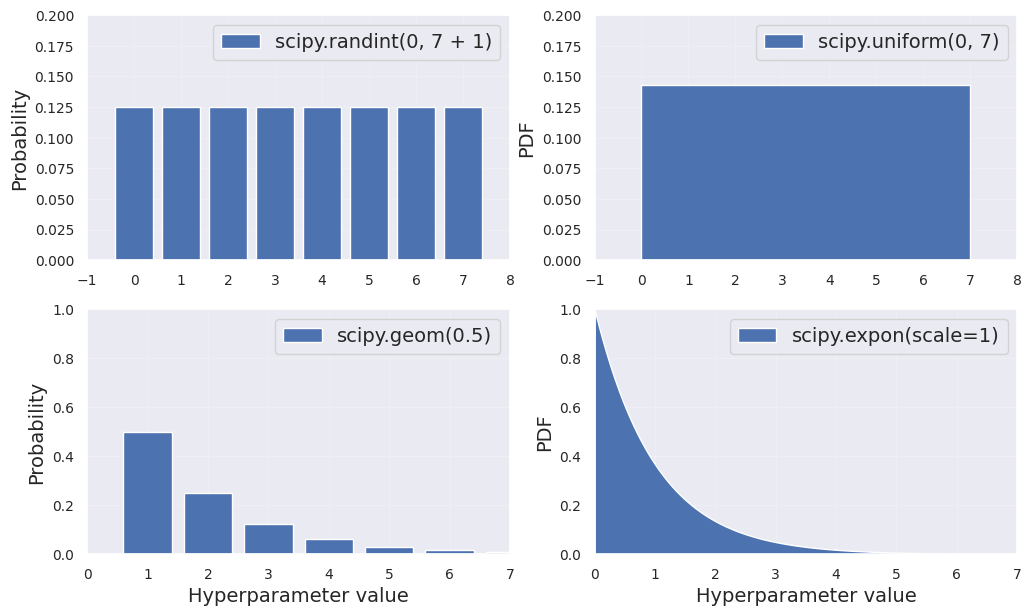

In [152]:
# extra code – plots a few distributions you can use in randomized search

from scipy.stats import randint, uniform, geom, expon

xs1 = np.arange(0, 7 + 1)
randint_distrib = randint(0, 7 + 1).pmf(xs1)

xs2 = np.linspace(0, 7, 500)
uniform_distrib = uniform(0, 7).pdf(xs2)

xs3 = np.arange(0, 7 + 1)
geom_distrib = geom(0.5).pmf(xs3)

xs4 = np.linspace(0, 7, 500)
expon_distrib = expon(scale=1).pdf(xs4)

plt.figure(figsize=(12, 7))

plt.subplot(2, 2, 1)
plt.bar(xs1, randint_distrib, label="scipy.randint(0, 7 + 1)")
plt.ylabel("Probability")
plt.legend()
plt.axis([-1, 8, 0, 0.2])

plt.subplot(2, 2, 2)
plt.fill_between(xs2, uniform_distrib, label="scipy.uniform(0, 7)")
plt.ylabel("PDF")
plt.legend()
plt.axis([-1, 8, 0, 0.2])

plt.subplot(2, 2, 3)
plt.bar(xs3, geom_distrib, label="scipy.geom(0.5)")
plt.xlabel("Hyperparameter value")
plt.ylabel("Probability")
plt.legend()
plt.axis([0, 7, 0, 1])

plt.subplot(2, 2, 4)
plt.fill_between(xs4, expon_distrib, label="scipy.expon(scale=1)")
plt.xlabel("Hyperparameter value")
plt.ylabel("PDF")
plt.legend()
plt.axis([0, 7, 0, 1])

plt.show()

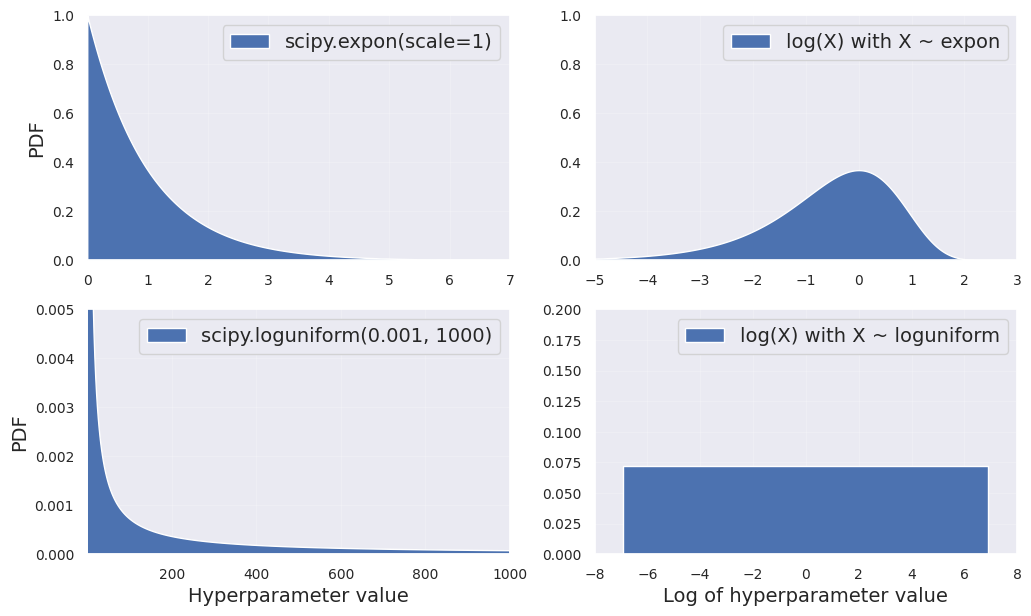

In [153]:
# extra code – shows the difference between expon and loguniform

from scipy.stats import loguniform

xs1 = np.linspace(0, 7, 500)
expon_distrib = expon(scale=1).pdf(xs1)

log_xs2 = np.linspace(-5, 3, 500)
log_expon_distrib = np.exp(log_xs2 - np.exp(log_xs2))

xs3 = np.linspace(0.001, 1000, 500)
loguniform_distrib = loguniform(0.001, 1000).pdf(xs3)

log_xs4 = np.linspace(np.log(0.001), np.log(1000), 500)
log_loguniform_distrib = uniform(loc=np.log(0.001),
                                 scale=np.log(1000) - np.log(0.001)).pdf(log_xs4)

plt.figure(figsize=(12, 7))

plt.subplot(2, 2, 1)
plt.fill_between(xs1, expon_distrib,
                 label="scipy.expon(scale=1)")
plt.ylabel("PDF")
plt.legend()
plt.axis([0, 7, 0, 1])

plt.subplot(2, 2, 2)
plt.fill_between(log_xs2, log_expon_distrib,
                 label="log(X) with X ~ expon")
plt.legend()
plt.axis([-5, 3, 0, 1])

plt.subplot(2, 2, 3)
plt.fill_between(xs3, loguniform_distrib,
                 label="scipy.loguniform(0.001, 1000)")
plt.xlabel("Hyperparameter value")
plt.ylabel("PDF")
plt.legend()
plt.axis([0.001, 1000, 0, 0.005])

plt.subplot(2, 2, 4)
plt.fill_between(log_xs4, log_loguniform_distrib,
                 label="log(X) with X ~ loguniform")
plt.xlabel("Log of hyperparameter value")
plt.legend()
plt.axis([-8, 8, 0, 0.2])

plt.show()

In [154]:
final_model = rnd_search.best_estimator_  # includes preprocessing
feature_importances = final_model["random_forest"].feature_importances_
feature_importances.round(2)

array([0.07, 0.05, 0.05, 0.01, 0.01, 0.01, 0.01, 0.19, 0.01, 0.02, 0.01,
       0.01, 0.01, 0.  , 0.01, 0.02, 0.01, 0.02, 0.01, 0.  , 0.01, 0.02,
       0.01, 0.01, 0.01, 0.  , 0.02, 0.01, 0.01, 0.  , 0.01, 0.01, 0.01,
       0.03, 0.01, 0.01, 0.01, 0.01, 0.04, 0.01, 0.02, 0.01, 0.02, 0.01,
       0.02, 0.02, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.  , 0.07,
       0.  , 0.  , 0.  , 0.01])

In [155]:
sorted(zip(feature_importances,
           final_model["preprocessing"].get_feature_names_out()),
       reverse=True)

[(np.float64(0.18599734460509476), 'log__median_income'),
 (np.float64(0.07338850855844489), 'cat__ocean_proximity_INLAND'),
 (np.float64(0.06556941990883976), 'bedrooms__ratio'),
 (np.float64(0.053648710076725316), 'rooms_per_house__ratio'),
 (np.float64(0.04598870861894749), 'people_per_house__ratio'),
 (np.float64(0.04175269214442519), 'geo__Cluster 30 similarity'),
 (np.float64(0.025976797232869678), 'geo__Cluster 25 similarity'),
 (np.float64(0.023595895886342255), 'geo__Cluster 36 similarity'),
 (np.float64(0.02021056221732893), 'geo__Cluster 9 similarity'),
 (np.float64(0.01860691707666145), 'geo__Cluster 34 similarity'),
 (np.float64(0.018137988374628867), 'geo__Cluster 37 similarity'),
 (np.float64(0.01740435316632675), 'geo__Cluster 18 similarity'),
 (np.float64(0.016778386143844894), 'geo__Cluster 1 similarity'),
 (np.float64(0.015459009666188978), 'geo__Cluster 7 similarity'),
 (np.float64(0.015325731028175924), 'geo__Cluster 32 similarity'),
 (np.float64(0.0150737720150383

In [156]:
X_test = strat_test_set.drop("median_house_value", axis=1)
y_test = strat_test_set["median_house_value"].copy()

final_predictions = final_model.predict(X_test)

final_rmse = root_mean_squared_error(y_test, final_predictions)
print(final_rmse)

41445.533268606625


In [157]:
from scipy.stats import bootstrap

def rmse(squared_errors):
    return np.sqrt(np.mean(squared_errors))

confidence = 0.95
squared_errors = (final_predictions - y_test) ** 2
boot_result = bootstrap([squared_errors], rmse, confidence_level=confidence,
                        random_state=42)
rmse_lower, rmse_upper = boot_result.confidence_interval

In [158]:
print(f"95% CI for RMSE: ({rmse_lower:.4f}, {rmse_upper:.4f})")

95% CI for RMSE: (39520.9572, 43701.7681)


In [159]:
import joblib

joblib.dump(final_model, "my_california_housing_model.pkl")

['my_california_housing_model.pkl']

In [160]:
import joblib

# extra code – excluded for conciseness
from sklearn.cluster import KMeans
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics.pairwise import rbf_kernel

def column_ratio(X):
    return X[:, [0]] / X[:, [1]]

def ratio_name(function_transformer, feature_names_in):
    return ["ratio"]

#class ClusterSimilarity(BaseEstimator, TransformerMixin):
#    [...]

final_model_reloaded = joblib.load("my_california_housing_model.pkl")

new_data = housing.iloc[:5]  # pretend these are new districts
predictions = final_model_reloaded.predict(new_data)

In [161]:
predictions

array([441046.12, 454713.09, 104832.  , 101316.  , 336181.05])

Ex #1

In [162]:
X_small = housing.iloc[:5000]
y_small = housing_labels.iloc[:5000]

print(X_small.shape)
print(y_small.shape)

(5000, 9)
(5000,)


In [163]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR

svr_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("svr", SVR())
])

In [164]:
param_grid = [
    {
        "svr__kernel": ["linear"],
        "svr__C": [
            10., 30., 100., 300.,
            1000., 3000., 10000., 30000.
        ]
    },
    {
        "svr__kernel": ["rbf"],
        "svr__C": [
            1., 3., 10., 30.,
            100., 300., 1000.
        ],
        "svr__gamma": [
            0.01, 0.03, 0.1, 0.3, 1., 3.
        ]
    }
]

In [165]:
from sklearn.model_selection import GridSearchCV

svr_grid_search = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="neg_root_mean_squared_error",
    verbose=2
)

In [166]:
svr_grid_search.fit(X_small, y_small)

Fitting 3 folds for each of 50 candidates, totalling 150 fits
[CV] END ....................svr__C=10.0, svr__kernel=linear; total time=   1.5s
[CV] END ....................svr__C=10.0, svr__kernel=linear; total time=   0.9s
[CV] END ....................svr__C=10.0, svr__kernel=linear; total time=   1.5s
[CV] END ....................svr__C=30.0, svr__kernel=linear; total time=   0.8s
[CV] END ....................svr__C=30.0, svr__kernel=linear; total time=   0.8s
[CV] END ....................svr__C=30.0, svr__kernel=linear; total time=   0.9s
[CV] END ...................svr__C=100.0, svr__kernel=linear; total time=   0.8s
[CV] END ...................svr__C=100.0, svr__kernel=linear; total time=   0.9s
[CV] END ...................svr__C=100.0, svr__kernel=linear; total time=   0.8s
[CV] END ...................svr__C=300.0, svr__kernel=linear; total time=   0.5s
[CV] END ...................svr__C=300.0, svr__kernel=linear; total time=   0.5s
[CV] END ...................svr__C=300.0, svr__

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                                                     SimpleImputer(strategy='median')),
                                                                                    ('standardscaler',
                                                                                     StandardScaler())]),
                                                          transformers=[('bedrooms',
                                                                         Pipeline(steps=[('simpleimputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('functiontransformer',
                                                                                          FunctionTransformer(feature_names_out=<f...
                                                                         <sklearn.compose._column_transformer.make_column_selector object at 0x7a4cad937ed0>)])),
                                       ('svr', SVR())]),
             param_grid=[{'svr__C': [10.0, 30.0, 100.0, 300.0, 1000.0, 3000.0,
                                     10000.0, 30000.0],
                          'svr__kernel': ['linear']},
                         {'svr__C': [1.0, 3.0, 10.0, 30.0, 100.0, 300.0,
                                     1000.0],
                          'svr__gamma': [0.01, 0.03, 0.1, 0.3, 1.0, 3.0],
                          'svr__kernel': ['rbf']}],
             scoring='neg_root_mean_squared_error', verbose=2)

In [167]:
print("Best parameters:")
print(svr_grid_search.best_params_)

best_cv_rmse = -svr_grid_search.best_score_

print(f"\nBest cross-validation RMSE: ${best_cv_rmse:,.2f}")

Best parameters:
{'svr__C': 10000.0, 'svr__kernel': 'linear'}

Best cross-validation RMSE: $70,059.93


The best SVR used a [linear] kernel with C = [10000], achieving a mean three-fold cross-validation RMSE of approximately $70,059.93 on the first 5,000 training examples.

Ex #2

In [169]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, expon

In [170]:
param_distribs = {
    "svr__kernel": ["linear", "rbf"],
    "svr__C": loguniform(20, 200_000),
    "svr__gamma": expon(scale=1.0)
}

In [171]:
svr_rnd_search = RandomizedSearchCV(
    estimator=svr_pipeline,
    param_distributions=param_distribs,
    n_iter=50,
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    verbose=2
)

In [172]:
svr_rnd_search.fit(
    housing.iloc[:5000],
    housing_labels.iloc[:5000]
)

Fitting 3 folds for each of 50 candidates, totalling 150 fits
[CV] END svr__C=629.7823295913721, svr__gamma=3.010121430917521, svr__kernel=linear; total time=   0.8s
[CV] END svr__C=629.7823295913721, svr__gamma=3.010121430917521, svr__kernel=linear; total time=   1.2s
[CV] END svr__C=629.7823295913721, svr__gamma=3.010121430917521, svr__kernel=linear; total time=   1.1s
[CV] END svr__C=26290.20646430022, svr__gamma=0.9084469696321253, svr__kernel=rbf; total time=   1.7s
[CV] END svr__C=26290.20646430022, svr__gamma=0.9084469696321253, svr__kernel=rbf; total time=   1.4s
[CV] END svr__C=26290.20646430022, svr__gamma=0.9084469696321253, svr__kernel=rbf; total time=   1.4s
[CV] END svr__C=84.14107900575871, svr__gamma=0.059838768608680676, svr__kernel=rbf; total time=   1.7s
[CV] END svr__C=84.14107900575871, svr__gamma=0.059838768608680676, svr__kernel=rbf; total time=   0.8s
[CV] END svr__C=84.14107900575871, svr__gamma=0.059838768608680676, svr__kernel=rbf; total time=   0.7s
[CV] END

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessing',
                                              ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                                                           SimpleImputer(strategy='median')),
                                                                                          ('standardscaler',
                                                                                           StandardScaler())]),
                                                                transformers=[('bedrooms',
                                                                               Pipeline(steps=[('simpleimputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('functiontransformer',
                                                                                                FunctionTransformer(feature_names_...
                                                                               <sklearn.compose._column_transformer.make_column_selector object at 0x7a4cad937ed0>)])),
                                             ('svr', SVR())]),
                   n_iter=50,
                   param_distributions={'svr__C': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7a4cc1241010>,
                                        'svr__gamma': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7a4cc456b350>,
                                        'svr__kernel': ['linear', 'rbf']},
                   random_state=42, scoring='neg_root_mean_squared_error',
                   verbose=2)

In [173]:
print("Best hyperparameters:")
print(svr_rnd_search.best_params_)

svr_rnd_search_rmse = -svr_rnd_search.best_score_

print(f"\nBest CV RMSE: ${svr_rnd_search_rmse:,.2f}")

Best hyperparameters:
{'svr__C': np.float64(157055.10989448498), 'svr__gamma': np.float64(0.26497040005002437), 'svr__kernel': 'rbf'}

Best CV RMSE: $56,152.05


In [174]:
grid_rmse = -svr_grid_search.best_score_
random_rmse = -svr_rnd_search.best_score_

improvement = 100 * (grid_rmse - random_rmse) / grid_rmse

print(f"Grid search RMSE:       ${grid_rmse:,.2f}")
print(f"Randomized search RMSE: ${random_rmse:,.2f}")
print(f"RMSE reduction:         {improvement:.1f}%")

Grid search RMSE:       $70,059.93
Randomized search RMSE: $56,152.05
RMSE reduction:         19.9%


I replaced GridSearchCV with RandomizedSearchCV, sampling 50 hyperparameter combinations using three-fold cross-validation on 5,000 training examples. The best model used [kernel: rbf
C: approximately 157,055.11
gamma: approximately 0.26497] and achieved a cross-validation RMSE of [$56,152.05].

Ex #3

In [175]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import cross_val_score

In [176]:
best_svr_params = svr_rnd_search.best_params_

print(best_svr_params)

{'svr__C': np.float64(157055.10989448498), 'svr__gamma': np.float64(0.26497040005002437), 'svr__kernel': 'rbf'}


In [177]:
selector_pipeline = Pipeline([
    ("preprocessing", preprocessing),

    ("selector", SelectFromModel(
        estimator=RandomForestRegressor(random_state=42),
        threshold=0.005
    )),

    ("svr", SVR(
        kernel=best_svr_params["svr__kernel"],
        C=best_svr_params["svr__C"],
        gamma=best_svr_params["svr__gamma"]
    ))
])

In [178]:
selector_rmses = -cross_val_score(
    selector_pipeline,
    housing.iloc[:5000],
    housing_labels.iloc[:5000],
    scoring="neg_root_mean_squared_error",
    cv=3
)

print("RMSE for each fold:")
print(selector_rmses)

print(f"\nMean CV RMSE: ${selector_rmses.mean():,.2f}")

RMSE for each fold:
[58770.91145669 56853.77669594 54243.24228971]

Mean CV RMSE: $56,622.64


In [179]:
before_rmse = -svr_rnd_search.best_score_
after_rmse = selector_rmses.mean()

print(f"Without selection: ${before_rmse:,.2f}")
print(f"With selection:    ${after_rmse:,.2f}")

difference = after_rmse - before_rmse

print(f"RMSE change:       ${difference:,.2f}")

Without selection: $56,152.05
With selection:    $56,622.64
RMSE change:       $470.59


I added a SelectFromModel transformer using a random forest with an importance threshold of 0.005. The mean three-fold cross-validation RMSE changed from [$56,152.05] to [$56,622.64]. Therefore, feature selection [did not improve] performance with these settings.

Ex #4

In [180]:
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR

In [181]:
class FeatureFromRegressor(TransformerMixin, BaseEstimator):
    def __init__(self, regressor, target_features):
        self.regressor = regressor
        self.target_features = target_features

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]

        self.input_features_ = [
            column for column in X.columns
            if column not in self.target_features
        ]

        self.regressor_ = clone(self.regressor)

        self.regressor_.fit(
            X[self.input_features_],
            X[self.target_features]
        )

        return self

    def transform(self, X):
        predictions = self.regressor_.predict(
            X[self.input_features_]
        )

        return np.asarray(predictions).reshape(
            len(X), len(self.target_features)
        )

    def fit_transform(self, X, y=None, **fit_params):
        self.fit(X, y)

        predictions = cross_val_predict(
            clone(self.regressor),
            X[self.input_features_],
            X[self.target_features],
            cv=5
        )

        return np.asarray(predictions).reshape(
            len(X), len(self.target_features)
        )

    def get_feature_names_out(self, input_features=None):
        return np.asarray([
            f"pred_{column}"
            for column in self.target_features
        ], dtype=object)

In [184]:
knn_transformer = FeatureFromRegressor(
    regressor=KNeighborsRegressor(
        n_neighbors=3,
        weights="distance"
    ),
    target_features=["median_income"]
)

geo_features = housing[
    ["latitude", "longitude", "median_income"]
]

income_features = knn_transformer.fit_transform(geo_features)

print(income_features.shape)

display(pd.DataFrame(
    income_features,
    columns=knn_transformer.get_feature_names_out(),
    index=geo_features.index
).head())

(16512, 1)


,pred_median_income
13096,3.422367
14973,7.711200
3785,4.163000
14689,2.540230
20507,3.448850


In [185]:
transformers = [
    (name, clone(transformer), columns)
    for name, transformer, columns in preprocessing.transformers
]

geo_index = [
    name for name, _, _ in transformers
].index("geo")

transformers[geo_index] = (
    "geo",
    clone(knn_transformer),
    ["latitude", "longitude", "median_income"]
)

new_geo_preprocessing = ColumnTransformer(
    transformers=transformers,
    remainder=clone(preprocessing.remainder)
)

In [186]:
best_svr_params = svr_rnd_search.best_params_

new_geo_pipeline = Pipeline([
    ("preprocessing", new_geo_preprocessing),

    ("svr", SVR(
        kernel=best_svr_params["svr__kernel"],
        C=best_svr_params["svr__C"],
        gamma=best_svr_params["svr__gamma"]
    ))
])

In [187]:
new_geo_rmses = -cross_val_score(
    new_geo_pipeline,
    housing.iloc[:5000],
    housing_labels.iloc[:5000],
    scoring="neg_root_mean_squared_error",
    cv=3
)

print("RMSE per fold:", new_geo_rmses)
print(f"Mean CV RMSE: ${new_geo_rmses.mean():,.2f}")

RMSE per fold: [62469.58473394 61192.10680528 59447.14677093]
Mean CV RMSE: $61,036.28


I created a KNN transformer that predicts median income from latitude and longitude. I replaced the geographic cluster-similarity features with this prediction. The resulting mean cross-validation RMSE was [$61,036.28], which was [worse] than the original SVR pipeline.

EX #5

In [188]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, expon

geo_param_distribs = {
    "preprocessing__geo__regressor__n_neighbors": range(1, 30),
    "preprocessing__geo__regressor__weights": [
        "distance", "uniform"
    ],
    "svr__C": loguniform(20, 200_000),
    "svr__gamma": expon(scale=1.0)
}

In [189]:
new_geo_rnd_search = RandomizedSearchCV(
    estimator=new_geo_pipeline,
    param_distributions=geo_param_distribs,
    n_iter=50,
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    verbose=2
)

In [190]:
new_geo_rnd_search.fit(
    housing.iloc[:5000],
    housing_labels.iloc[:5000]
)

Fitting 3 folds for each of 50 candidates, totalling 150 fits
[CV] END preprocessing__geo__regressor__n_neighbors=7, preprocessing__geo__regressor__weights=uniform, svr__C=127024.42021281396, svr__gamma=1.3167456935454493; total time=   2.2s
[CV] END preprocessing__geo__regressor__n_neighbors=7, preprocessing__geo__regressor__weights=uniform, svr__C=127024.42021281396, svr__gamma=1.3167456935454493; total time=   1.6s
[CV] END preprocessing__geo__regressor__n_neighbors=7, preprocessing__geo__regressor__weights=uniform, svr__C=127024.42021281396, svr__gamma=1.3167456935454493; total time=   1.5s
[CV] END preprocessing__geo__regressor__n_neighbors=29, preprocessing__geo__regressor__weights=distance, svr__C=84.15977339213268, svr__gamma=0.16959629191460518; total time=   0.7s
[CV] END preprocessing__geo__regressor__n_neighbors=29, preprocessing__geo__regressor__weights=distance, svr__C=84.15977339213268, svr__gamma=0.16959629191460518; total time=   0.7s
[CV] END preprocessing__geo__regre

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessing',
                                              ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                                                           SimpleImputer(strategy='median')),
                                                                                          ('standardscaler',
                                                                                           StandardScaler())]),
                                                                transformers=[('bedrooms',
                                                                               Pipeline(steps=[('simpleimputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('functiontransformer',
                                                                                                FunctionTransformer(feature_names_...
                   param_distributions={'preprocessing__geo__regressor__n_neighbors': range(1, 30),
                                        'preprocessing__geo__regressor__weights': ['distance',
                                                                                   'uniform'],
                                        'svr__C': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7a4cc6d99590>,
                                        'svr__gamma': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7a4cad7fa650>},
                   random_state=42, scoring='neg_root_mean_squared_error',
                   verbose=2)

In [191]:
print("Best settings:")

for parameter, value in new_geo_rnd_search.best_params_.items():
    print(f"{parameter}: {value}")

new_geo_rnd_search_rmse = -new_geo_rnd_search.best_score_

print(f"\nBest CV RMSE: ${new_geo_rnd_search_rmse:,.2f}")

Best settings:
preprocessing__geo__regressor__n_neighbors: 12
preprocessing__geo__regressor__weights: distance
svr__C: 43033.794596166656
svr__gamma: 0.19039161651674988

Best CV RMSE: $59,275.19


In [192]:
new_geo_rnd_search.best_params_[
    "preprocessing__geo__regressor__n_neighbors"
]

12

In [193]:
comparison = pd.DataFrame({
    "Approach": [
        "Original geographic features: EX #2",
        "KNN income feature: Ex #4",
        "Tuned KNN income feature: Ex #5"
    ],
    "CV RMSE": [
        -svr_rnd_search.best_score_,
        new_geo_rmses.mean(),
        new_geo_rnd_search_rmse
    ]
})

display(comparison.round(2))

,Approach,CV RMSE
0,Original geographic features: EX #2,56152.05
1,KNN income feature: Ex #4,61036.28
2,Tuned KNN income feature: Ex #5,59275.19


I used RandomizedSearchCV to jointly tune the KNN preprocessing settings and SVR hyperparameters. The best combination used [12] neighbors with [distance] weighting and achieved a cross-validation RMSE of [$59,275.19]. This was [better] than the untuned KNN pipeline and [worse] than the original geographic features.

Ex #6

In [194]:
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import (
    check_array,
    check_is_fitted,
    validate_data
)

In [195]:
class StandardScalerClone(TransformerMixin, BaseEstimator):
    def __init__(self, with_mean=True):
        self.with_mean = with_mean

    def fit(self, X, y=None):
        X = validate_data(self, X, dtype=np.float64)

        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0, ddof=0)

        # Constant columns must not cause division by zero.
        self.scale_[self.scale_ == 0] = 1.0

        return self

    def transform(self, X):
        check_is_fitted(self, ["mean_", "scale_"])

        X = validate_data(
            self, X, reset=False, dtype=np.float64
        )

        if self.with_mean:
            X = X - self.mean_

        return X / self.scale_

    def inverse_transform(self, X):
        check_is_fitted(self, ["mean_", "scale_"])

        X = check_array(X, dtype=np.float64)

        if X.shape[1] != self.n_features_in_:
            raise ValueError("Unexpected number of features")

        X = X * self.scale_

        if self.with_mean:
            X = X + self.mean_

        return X

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, ["mean_", "scale_"])

        if input_features is not None:
            input_features = np.asarray(
                input_features, dtype=object
            )

            if (
                input_features.ndim != 1
                or len(input_features) != self.n_features_in_
            ):
                raise ValueError("Invalid number of feature names")

            if hasattr(self, "feature_names_in_"):
                if not np.array_equal(
                    input_features, self.feature_names_in_
                ):
                    raise ValueError(
                        "Feature names do not match training columns"
                    )

            return input_features

        if hasattr(self, "feature_names_in_"):
            return self.feature_names_in_.copy()

        return np.asarray(
            [f"x{i}" for i in range(self.n_features_in_)],
            dtype=object
        )

In [196]:
X_example = pd.DataFrame({
    "income": [2.0, 4.0, 6.0],
    "rooms": [100.0, 200.0, 300.0],
    "constant": [5.0, 5.0, 5.0]
})

scaler = StandardScalerClone()

X_scaled = scaler.fit_transform(X_example)
X_restored = scaler.inverse_transform(X_scaled)

print("Scaled values:")
print(X_scaled)

print("\nRestored values:")
print(X_restored)

print(
    "\nMatches original:",
    np.allclose(X_restored, X_example.to_numpy())
)

Scaled values:
[[-1.22474487 -1.22474487  0.        ]
 [ 0.          0.          0.        ]
 [ 1.22474487  1.22474487  0.        ]]

Restored values:
[[  2. 100.   5.]
 [  4. 200.   5.]
 [  6. 300.   5.]]

Matches original: True


In [197]:
print(scaler.feature_names_in_)
print(scaler.get_feature_names_out())

['income' 'rooms' 'constant']
['income' 'rooms' 'constant']


In [198]:
print(scaler.get_feature_names_out(
    ["income", "rooms", "constant"]
))

['income' 'rooms' 'constant']


In [199]:
array_scaler = StandardScalerClone()
array_scaler.fit(X_example.to_numpy())

print(array_scaler.get_feature_names_out())

['x0' 'x1' 'x2']


In [200]:
from sklearn.preprocessing import StandardScaler

expected = StandardScaler().fit_transform(X_example)

print(np.allclose(X_scaled, expected))

True


In [201]:
scaler_no_center = StandardScalerClone(with_mean=False)

scaled = scaler_no_center.fit_transform(X_example)
restored = scaler_no_center.inverse_transform(scaled)

print(np.allclose(restored, X_example.to_numpy()))

True


Ex #7A - Bike rental prediction

In [202]:
import io
import urllib.request
import zipfile
import pandas as pd

bike_url = (
    "https://archive.ics.uci.edu/static/public/275/"
    "bike+sharing+dataset.zip"
)

with urllib.request.urlopen(bike_url) as bike_response:
    bike_zip_bytes = bike_response.read()

with zipfile.ZipFile(io.BytesIO(bike_zip_bytes)) as bike_archive:
    with bike_archive.open("hour.csv") as bike_file:
        bike_data = pd.read_csv(bike_file)

print("Rows and columns:", bike_data.shape)
display(bike_data.head())

Rows and columns: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [209]:
bike_data.head(-10)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17364,17365,2012-12-31,1,1,12,9,0,1,1,2,0.18,0.2121,0.64,0.1045,13,144,157
17365,17366,2012-12-31,1,1,12,10,0,1,1,2,0.20,0.2121,0.69,0.1343,33,87,120
17366,17367,2012-12-31,1,1,12,11,0,1,1,2,0.22,0.2273,0.60,0.1940,43,114,157
17367,17368,2012-12-31,1,1,12,12,0,1,1,2,0.24,0.2273,0.56,0.1940,52,172,224


In [207]:
bike_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [210]:
bike_clean = bike_data.copy()

bike_clean["dteday"] = pd.to_datetime(bike_clean["dteday"])

bike_clean = bike_clean.sort_values(
    ["dteday", "hr"]
).reset_index(drop=True)

bike_dates = bike_clean["dteday"].drop_duplicates()
bike_cutoff = bike_dates.iloc[int(len(bike_dates) * 0.8)]

bike_train = bike_clean.loc[
    bike_clean["dteday"] < bike_cutoff
].copy()

bike_test = bike_clean.loc[
    bike_clean["dteday"] >= bike_cutoff
].copy()

print("Bike training rows:", len(bike_train))
print("Bike test rows:", len(bike_test))
print("Test starts:", bike_cutoff.date())

Bike training rows: 13891
Bike test rows: 3488
Test starts: 2012-08-07


In [213]:
bike_drop_columns = [
    "cnt",
    "casual",
    "registered",
    "instant",
    "dteday"
]

bike_X_train = bike_train.drop(columns=bike_drop_columns)
bike_y_train = bike_train["cnt"].copy()

print("Bike inputs:", bike_X_train.shape)

Bike inputs: (13891, 12)


In [215]:
bike_num_columns = [
    "temp", "atemp", "hum", "windspeed"
]

bike_cat_columns = [
    "season", "yr", "mnth", "hr",
    "holiday", "weekday", "workingday", "weathersit"
]

bike_num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

bike_cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

bike_preprocessing = ColumnTransformer([
    ("num", bike_num_pipeline, bike_num_columns),
    ("cat", bike_cat_pipeline, bike_cat_columns)
])

In [216]:
assert set(bike_X_train.columns) == set(
    bike_num_columns + bike_cat_columns
)

print("preprocessing definitions cover all input columns.")

preprocessing definitions cover all input columns.


In [218]:
from sklearn.model_selection import KFold, TimeSeriesSplit

bike_cv = TimeSeriesSplit(n_splits=3)

In [220]:
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

bike_models = {
    "Baseline": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

In [222]:
bike_results = []

for bike_name, bike_model in bike_models.items():
    bike_pipeline = Pipeline([
        ("preprocessing", clone(bike_preprocessing)),
        ("model", clone(bike_model))
    ])

    bike_scores = -cross_val_score(
        bike_pipeline,
        bike_X_train,
        bike_y_train,
        cv=bike_cv,
        scoring="neg_root_mean_squared_error"
    )

    bike_results.append({
        "Model": bike_name,
        "Mean CV RMSE": bike_scores.mean(),
        "Fold RMSE std": bike_scores.std()
    })

bike_results_table = pd.DataFrame(
    bike_results
).sort_values("Mean CV RMSE")

display(bike_results_table.round(2))

,Model,Mean CV RMSE,Fold RMSE std
2,Random forest,96.24,12.89
1,Linear regression,111.08,19.71
0,Baseline,181.75,48.50


In [224]:
bike_rf_pipeline = Pipeline([
    ("preprocessing", clone(bike_preprocessing)),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

bike_param_distributions = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.5, 0.8, 1.0]
}

bike_search = RandomizedSearchCV(
    bike_rf_pipeline,
    param_distributions=bike_param_distributions,
    n_iter=12,
    cv=bike_cv,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

bike_search.fit(bike_X_train, bike_y_train)

print("Best settings:", bike_search.best_params_)
print(f"Best CV RMSE: {-bike_search.best_score_:,.2f}")

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best settings: {'model__n_estimators': 300, 'model__min_samples_leaf': 1, 'model__max_features': 0.8, 'model__max_depth': None}
Best CV RMSE: 96.28


In [225]:
bike_final_model = Pipeline([
    ("preprocessing", clone(bike_preprocessing)),
    ("model", clone(bike_models["Random forest"]))
])

bike_final_model.fit(bike_X_train, bike_y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['temp', 'atemp', 'hum',
                                                   'windspeed']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['season', 'yr', 'mnth', 'hr',
                                                   'holiday', 'weekday',
                                                   'workingday',
                                                   'weathersit'])])),
                ('model', RandomForestRegressor(n_jobs=-1, random_state=42))])

In [228]:
bike_X_test = bike_test.drop(columns=bike_drop_columns)
bike_y_test = bike_test["cnt"].copy()

In [229]:
from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score
)

bike_test_predictions = bike_final_model.predict(
    bike_X_test
)

bike_test_metrics = {
    "Project": "Bikes",
    "Test RMSE": root_mean_squared_error(
        bike_y_test, bike_test_predictions
    ),
    "Test MAE": mean_absolute_error(
        bike_y_test, bike_test_predictions
    ),
    "Test R²": r2_score(
        bike_y_test, bike_test_predictions
    )
}

display(pd.DataFrame([
    bike_test_metrics
]).round(2))

,Project,Test RMSE,Test MAE,Test R²
0,Bikes,82.26,54.52,0.86


### Bike rental prediction
I reserved the latest 20% of dates for testing and used chronological
cross-validation. I excluded casual and registered counts because
they directly reveal the target label "cnt".

Random forest outperformed the baseline and linear regression.
Tuning did not improve validation performance, so I retained the
original forest.

The selected model achieved:
- Test RMSE: 82.26 rentals per hour
- Test MAE: 54.52 rentals per hour
- Test R²: 0.86

These results assume weather conditions for the prediction hour are
available. Advance forecasting would require forecast weather inputs.

Ex #7B - Vehicle price prediction

In [203]:
%pip -q install kagglehub

In [204]:
import kagglehub
from pathlib import Path

vehicle_folder = Path(
    kagglehub.dataset_download(
        "nehalbirla/vehicle-dataset-from-cardekho"
    )
)

vehicle_csv_files = sorted(vehicle_folder.rglob("*.csv"))

print("Available files:")
for vehicle_file in vehicle_csv_files:
    print(vehicle_file.name)

100%|██████████| 292k/292k [00:00<00:00, 78.5MB/s]

Extracting files...
Available files:
CAR DETAILS FROM CAR DEKHO.csv
Car details v3.csv
car data.csv
car details v4.csv


In [205]:
vehicle_data = pd.read_csv(
    vehicle_folder / "Car details v3.csv"
)

print("Vehicle shape:", vehicle_data.shape)
display(vehicle_data.head())
vehicle_data.info()

Vehicle shape: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 825.6+ KB


In [208]:
from sklearn.model_selection import train_test_split

vehicle_clean = vehicle_data.drop_duplicates().copy()

vehicle_train, vehicle_test = train_test_split(
    vehicle_clean,
    test_size=0.2,
    random_state=42
)

vehicle_train = vehicle_train.copy()
vehicle_test = vehicle_test.copy()

print("Vehicle training rows:", len(vehicle_train))
print("Vehicle test rows:", len(vehicle_test))

Vehicle training rows: 5540
Vehicle test rows: 1386


In [211]:
def vehicle_prepare_inputs(vehicle_frame):
    vehicle_features = vehicle_frame.drop(
        columns=["selling_price", "torque", "mileage"]
    ).copy()

    for vehicle_column in ["engine", "max_power"]:
        vehicle_features[vehicle_column] = pd.to_numeric(
            vehicle_features[vehicle_column]
            .astype("string")
            .str.extract(r"(\d+(?:\.\d+)?)", expand=False),
            errors="coerce"
        )

    return vehicle_features


vehicle_X_train = vehicle_prepare_inputs(vehicle_train)
vehicle_y_train = vehicle_train["selling_price"].copy()

display(vehicle_X_train.head())
print(vehicle_X_train.isna().sum())

,name,year,km_driven,fuel,seller_type,transmission,owner,engine,max_power,seats
5586,Ford EcoSport 1.5 Diesel Titanium BSIV,2018,25000,Diesel,Individual,Manual,First Owner,1498,98.96,5.0
3468,Maruti Omni E 8 Str STD,2010,170000,Petrol,Individual,Manual,Second Owner,<NA>,<NA>,NaN
4935,Hyundai i20 1.4 CRDi Asta,2011,75500,Diesel,Individual,Manual,Second Owner,1396,90.0,5.0
2485,Maruti Swift Dzire VDi,2009,138000,Diesel,Individual,Manual,Second Owner,1248,73.9,5.0
4491,Hyundai Accent DLS,2003,200000,Diesel,Individual,Manual,Second Owner,1493,82.0,5.0


name              0
year              0
km_driven         0
fuel              0
seller_type       0
transmission      0
owner             0
engine          172
max_power       171
seats           172
dtype: int64


In [212]:
print("Vehicle inputs:", vehicle_X_train.shape)

Vehicle inputs: (5540, 10)


In [214]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

vehicle_num_columns = vehicle_X_train.select_dtypes(
    include="number"
).columns.tolist()

vehicle_cat_columns = vehicle_X_train.select_dtypes(
    exclude="number"
).columns.tolist()

vehicle_num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

vehicle_cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

vehicle_preprocessing = ColumnTransformer([
    ("num", vehicle_num_pipeline, vehicle_num_columns),
    ("cat", vehicle_cat_pipeline, vehicle_cat_columns)
])

In [217]:
assert set(vehicle_X_train.columns) == set(
    vehicle_num_columns + vehicle_cat_columns
)

print("preprocessing definitions cover all input columns.")

preprocessing definitions cover all input columns.


In [ ]:
from sklearn.model_selection import KFold, TimeSeriesSplit

vehicle_cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [219]:
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

vehicle_models = {
    "Baseline": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

In [221]:
from sklearn.model_selection import cross_val_score

vehicle_results = []

for vehicle_name, vehicle_model in vehicle_models.items():
    vehicle_pipeline = Pipeline([
        ("preprocessing", clone(vehicle_preprocessing)),
        ("model", clone(vehicle_model))
    ])

    vehicle_scores = -cross_val_score(
        vehicle_pipeline,
        vehicle_X_train,
        vehicle_y_train,
        cv=vehicle_cv,
        scoring="neg_root_mean_squared_error"
    )

    vehicle_results.append({
        "Model": vehicle_name,
        "Mean CV RMSE": vehicle_scores.mean(),
        "Fold RMSE std": vehicle_scores.std()
    })

vehicle_results_table = pd.DataFrame(
    vehicle_results
).sort_values("Mean CV RMSE")

display(vehicle_results_table.round(2))

,Model,Mean CV RMSE,Fold RMSE std
2,Random forest,186717.82,9663.49
1,Linear regression,287485.17,31092.67
0,Baseline,531096.78,32974.03


In [223]:
from sklearn.model_selection import RandomizedSearchCV

vehicle_rf_pipeline = Pipeline([
    ("preprocessing", clone(vehicle_preprocessing)),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

vehicle_param_distributions = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.5, 0.8, 1.0]
}

vehicle_search = RandomizedSearchCV(
    vehicle_rf_pipeline,
    param_distributions=vehicle_param_distributions,
    n_iter=12,
    cv=vehicle_cv,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

vehicle_search.fit(vehicle_X_train, vehicle_y_train)

print("Best settings:", vehicle_search.best_params_)
print(f"Best CV RMSE: {-vehicle_search.best_score_:,.2f}")

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best settings: {'model__n_estimators': 300, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': 30}
Best CV RMSE: 183,556.51


In [226]:
vehicle_final_model = vehicle_search.best_estimator_

In [227]:
vehicle_X_test = vehicle_prepare_inputs(vehicle_test)
vehicle_y_test = vehicle_test["selling_price"].copy()

In [230]:
from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score
)

vehicle_test_predictions = vehicle_final_model.predict(
    vehicle_X_test
)

vehicle_test_metrics = {
    "Project": "Vehicles",
    "Test RMSE": root_mean_squared_error(
        vehicle_y_test, vehicle_test_predictions
    ),
    "Test MAE": mean_absolute_error(
        vehicle_y_test, vehicle_test_predictions
    ),
    "Test R²": r2_score(
        vehicle_y_test, vehicle_test_predictions
    )
}

display(pd.DataFrame([
    vehicle_test_metrics
]).round(2))

,Project,Test RMSE,Test MAE,Test R²
0,Vehicles,136744.02,73095.95,0.91


### Vehicle price prediction
I removed exact duplicate rows, reserved 20% of the data for testing,
and prepared numeric and categorical features using a pipeline.

Random forest outperformed the mean baseline and linear regression.
Randomized search slightly improved its cross-validation RMSE.

The selected model achieved:
- Test RMSE: 136,744.02
- Test MAE: 73,095.95
- Test R²: 0.91

Limitations include omitted mileage and torque features, and evaluation
on listings from the same dataset rather than a new market.